# Actividad: Auditoría Forense de Modelos de Riesgo Crediticio Basados en Árboles

## Maestría en Inteligencia Artificial Aplicada

**Tecnológico de Monterrey**

**Curso:** Inteligencia Artificial y Aprendizaje Automático

**Profesor:** Luis Eduardo Falcón Morales

**Nombre:** Carlos Rodrigo Salguero Alcántara

**Matrícula:** A00833341


## Introducción: auditoría de modelos de riesgo crediticio basados en árboles


### **Contexto del problema:**

- Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

- Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

- Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.

- Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.

- En particular, se espera que cumplas con los siguientes objetivos:
  - Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  - Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  - Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  - Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  - Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  - Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  - Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  - Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  - Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  - Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.


### **Descripción del negocio:**

- Cada vez que una solicitud de crédito es aprobada:
  - Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de \$100 USD.

  - Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de \$500 USD.

- Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
  - La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

  - La utilidad esperada utilizando un umbral optimizado.
  - El impacto económico estimado por cada 10,000 solicitudes evaluadas.


### Hoja de ruta: dónde se responde cada objetivo

| Objetivo de la actividad                                                   | Sección                          |
| -------------------------------------------------------------------------- | -------------------------------- |
| Identificar y documentar al menos 6 errores conceptuales o metodológicos   | 4.1 (12 errores documentados)    |
| Detectar fuga de información en los datos y en el proceso de entrenamiento | 4.2 y 4.3                        |
| Justificar la métrica y evaluar otras métricas                             | 6.0                              |
| Identificar evidencia de sub o sobreentrenamiento                          | 4.3, 7.0 y 7.2                   |
| Analizar el impacto del umbral de clasificación en el negocio              | 8.0 y 10.0                       |
| Decidir cuál de los 3 modelos desplegar                                    | 9.3 y 10.0                       |
| Identificar los 3 o 4 factores más importantes y su significado de negocio | 11.0 y 11.1                      |
| Reporte para los tomadores de decisiones                                   | 12.0 (Conclusiones particulares) |
| Uso de herramientas de IA generativa                                       | 13.0 (Conclusiones)              |

**Veredicto en una línea:** el modelo del analista junior **no debe desplegarse**: su desempeño perfecto proviene de una variable que sólo se conoce después de otorgar el crédito y de un balanceo de clases aplicado antes de separar los datos. La versión corregida (Random Forest con umbral de rechazo de 0.15) sí genera valor: **USD 508,667 por cada 10,000 solicitudes**, frente a USD 296,000 si se aprueba a todos y USD 348,000 con el umbral estándar de 0.5.


## 1.0 Configuración del notebook

Importaciones y versión de librerías. La semilla `RANDOM_STATE = 11` se conserva en todos los modelos, particiones, búsquedas y remuestreos, como lo pide la actividad.


In [1]:
import warnings

warnings.filterwarnings("ignore")

In [2]:
from __future__ import annotations

from dataclasses import dataclass
from itertools import combinations
from pathlib import Path
from typing import Any, Final

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import seaborn as sns

In [4]:
import shap
import sklearn

In [5]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from scipy.stats import loguniform, mannwhitneyu, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    make_scorer,
    roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [6]:
print(f"scikit-learn version: {sklearn.__version__}")

scikit-learn version: 1.9.1


### 1.1 Constantes, tipos de datos y estilo de gráficas

Se fijan tipos explícitos (`DTYPES`) al leer el CSV para validar el esquema y se agrupan las variables en continuas y discretas para el análisis exploratorio. La variable `dias_max_atraso_30d_despues` queda declarada desde aquí como `LEAKAGE_FEATURE` (ver sección 4.2).


In [7]:
RANDOM_STATE: Final[int] = 11
TARGET: Final[str] = "default_90d"
LEAKAGE_FEATURE: Final[str] = "dias_max_atraso_30d_despues"
TEST_SIZE: Final[float] = 0.30

In [8]:
DATA_PATH: Final[Path] = next(
    (
        candidate
        for candidate in (
            Path("data/fintech_default_risk.csv"),
            Path("fintech_default_risk.csv"),
        )
        if candidate.exists()
    ),
    Path("data/fintech_default_risk.csv"),
)

In [9]:
DTYPES: Final[dict[str, str]] = {
    "edad": "int16",
    "ingreso_mensual": "float64",
    "antiguedad_laboral_meses": "int16",
    "score_crediticio": "float64",
    "utilizacion_credito": "float64",
    "atrasos_12m": "int8",
    "consultas_buro_6m": "int8",
    "num_productos": "int8",
    "limite_credito": "float64",
    "deuda_total": "float64",
    "relacion_deuda_ingreso": "float64",
    "dias_max_atraso_30d_despues": "int16",
    "cliente_premium": "int8",
    "default_90d": "int8",
}

In [10]:
CONTINUOUS_FEATURES: Final[list[str]] = [
    "edad",
    "ingreso_mensual",
    "antiguedad_laboral_meses",
    "score_crediticio",
    "utilizacion_credito",
    "limite_credito",
    "deuda_total",
    "relacion_deuda_ingreso",
]

In [11]:
DISCRETE_FEATURES: Final[list[str]] = [
    "atrasos_12m",
    "consultas_buro_6m",
    "num_productos",
    "cliente_premium",
]

In [12]:
EDA_FEATURES: Final[list[str]] = CONTINUOUS_FEATURES + DISCRETE_FEATURES

In [13]:
pd.set_option("display.float_format", "{:,.4f}".format)

In [14]:
FIGURE_SIZE_SINGLE: Final[tuple[float, float]] = (8.0, 4.5)
FIGURE_SIZE_WIDE: Final[tuple[float, float]] = (10.0, 5.0)
FIGURE_SIZE_PANEL: Final[tuple[float, float]] = (16.0, 5.0)
FIGURE_SIZE_SQUARE: Final[tuple[float, float]] = (12.0, 5.0)
FIGURE_SIZE_HEATMAP: Final[tuple[float, float]] = (10.0, 8.0)

In [15]:
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": True,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

In [16]:
pio.renderers.default = "plotly_mimetype+notebook_connected"
pio.templates.default = "plotly_white"

CLASS_LABELS: Final[dict[int, str]] = {0: "No default", 1: "Default"}
CLASS_COLORS: Final[dict[str, str]] = {"No default": "#4C72B0", "Default": "#DD8452"}

## 2.0 Carga de datos y control de calidad

Se valida que el esquema coincida con la _Tabla de Variables_, que el objetivo sea binario y que no existan faltantes ni duplicados.


In [17]:
data: pd.DataFrame = pd.read_csv(DATA_PATH, dtype=DTYPES)

assert list(data.columns) == list(DTYPES), "Unexpected columns in source CSV"
assert data[TARGET].isin([0, 1]).all(), "Target must be binary {0, 1}"

display(data.dtypes.to_frame("dtype"))
display(data.head())

,dtype
edad,int16
ingreso_mensual,float64
antiguedad_laboral_meses,int16
score_crediticio,float64
utilizacion_credito,float64
atrasos_12m,int8
consultas_buro_6m,int8
num_productos,int8
limite_credito,float64
deuda_total,float64


,edad,ingreso_mensual,antiguedad_laboral_meses,score_crediticio,utilizacion_credito,atrasos_12m,consultas_buro_6m,num_productos,limite_credito,deuda_total,relacion_deuda_ingreso,dias_max_atraso_30d_despues,cliente_premium,default_90d
0,46,"34,959.9283",296,659.0939,0.4104,3,5,7,"209,105.3116","77,661.2717",2.2214,7,0,0
1,37,"8,659.8267",6,728.4567,0.8821,1,2,3,"44,070.5043","42,105.8379",4.8616,4,0,0
2,48,"11,502.4876",166,636.2618,0.4087,1,3,1,"42,132.2360","15,409.4964",1.3395,3,1,0
3,38,"27,870.5781",123,650.8291,0.1146,1,2,5,"132,010.1703","10,660.8433",0.3825,9,0,0
4,34,"23,048.6023",240,725.4979,0.1492,0,6,6,"100,877.8218","10,838.7442",0.4702,1,0,0


In [18]:
n_rows, n_cols = data.shape
print(f"Shape: {n_rows:,} rows x {n_cols} columns")
print(f"Duplicated rows: {int(data.duplicated().sum()):,}")
print(f"Total missing values: {int(data.isna().sum().sum()):,}")


Shape: 5,000 rows x 14 columns
Duplicated rows: 0
Total missing values: 0


In [19]:
missing_summary: pd.DataFrame = (
    data.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda df: (df["missing_count"] / len(data) * 100).round(2))
)

display(missing_summary)

,missing_count,missing_pct
edad,0,0.0000
ingreso_mensual,0,0.0000
antiguedad_laboral_meses,0,0.0000
score_crediticio,0,0.0000
utilizacion_credito,0,0.0000
atrasos_12m,0,0.0000
consultas_buro_6m,0,0.0000
num_productos,0,0.0000
limite_credito,0,0.0000
deuda_total,0,0.0000


### 2.1 Validación de dominio


In [20]:
DOMAIN_RULES: Final[dict[str, tuple[float, float]]] = {
    "edad": (18, 100),
    "ingreso_mensual": (0, np.inf),
    "antiguedad_laboral_meses": (0, np.inf),
    "score_crediticio": (300, 850),
    "utilizacion_credito": (0, 1),
    "atrasos_12m": (0, 12),
    "consultas_buro_6m": (0, np.inf),
    "num_productos": (1, np.inf),  # existing clients hold at least one product
    "limite_credito": (0, np.inf),
    "deuda_total": (0, np.inf),
    "relacion_deuda_ingreso": (0, np.inf),
    "dias_max_atraso_30d_despues": (0, np.inf),
    "cliente_premium": (0, 1),
    "default_90d": (0, 1),
}

In [21]:
def validate_domain(
    df: pd.DataFrame,
    rules: dict[str, tuple[float, float]] = DOMAIN_RULES,
) -> pd.DataFrame:
    """
    Count values outside the business-valid range of each variable.
    """

    rows: list[dict[str, Any]] = []
    for column, (low, high) in rules.items():
        values = df[column]
        rows.append(
            {
                "variable": column,
                "allowed_min": low,
                "allowed_max": high,
                "observed_min": values.min(),
                "observed_max": values.max(),
                "n_below": int((values < low).sum()),
                "n_above": int((values > high).sum()),
            }
        )

    return pd.DataFrame(rows).set_index("variable")

In [22]:
domain_report: pd.DataFrame = validate_domain(data)
display(domain_report)

n_violations = int(domain_report[["n_below", "n_above"]].to_numpy().sum())
print(f"Total out-of-domain values: {n_violations:,}")

,allowed_min,allowed_max,observed_min,observed_max,n_below,n_above
variable,,,,,,
edad,18,100.0000,21.0000,70.0000,0,0
ingreso_mensual,0,inf,"3,462.2944","132,627.2308",0,0
antiguedad_laboral_meses,0,inf,1.0000,359.0000,0,0
score_crediticio,300,850.0000,374.7155,850.0000,0,0
utilizacion_credito,0,1.0000,0.0049,0.9936,0,0
atrasos_12m,0,12.0000,0.0000,8.0000,0,0
consultas_buro_6m,0,inf,0.0000,12.0000,0,0
num_productos,1,inf,1.0000,7.0000,0,0
limite_credito,0,inf,"9,422.7657","747,982.8183",0,0


Total out-of-domain values: 0


In [23]:
score_at_cap: float = float((data["score_crediticio"] == 850).mean())
ratio_gap: pd.Series = (
    data["deuda_total"] / data["ingreso_mensual"] - data["relacion_deuda_ingreso"]
).abs()

print(f"Share of clients with score_crediticio capped at 850: {score_at_cap:.2%}")
print(
    "relacion_deuda_ingreso vs deuda_total / ingreso_mensual: "
    f"max abs difference = {ratio_gap.max():.5f}"
)

Share of clients with score_crediticio capped at 850: 2.68%
relacion_deuda_ingreso vs deuda_total / ingreso_mensual: max abs difference = 0.00082


**Hallazgos de calidad de datos**

- 5,000 clientes y 14 variables, sin valores faltantes ni filas duplicadas.
- Ningún valor queda fuera del rango de negocio de la _Tabla de Variables_ (por ejemplo, `score_crediticio` entre 300 y 850, `utilizacion_credito` entre 0 y 1, al menos un producto activo).
- El 2.68% de los clientes tiene `score_crediticio` exactamente en 850: la escala está topada en su máximo. Un modelo de árboles lo maneja sin problema, pero conviene tenerlo presente al interpretar.
- `relacion_deuda_ingreso` es, salvo redondeo (diferencia máxima de 0.0008), igual a `deuda_total / ingreso_mensual`: es una variable **derivada y redundante** (ver 3.6 y 5.2).


## 3.0 Análisis exploratorio de datos (EDA)

El EDA se realiza sobre las 12 variables candidatas (sin la variable con fuga, que se analiza en 4.2). Es descriptivo: ninguna decisión de modelado se toma con el conjunto de prueba, y las decisiones sobre variables se validan después usando sólo el conjunto de entrenamiento (sección 5.2).


### 3.1 Distribución de la variable objetivo


In [24]:
target_counts: pd.DataFrame = (
    data[TARGET]
    .map(CLASS_LABELS)
    .value_counts()
    .rename_axis("class")
    .reset_index(name="count")
    .assign(share=lambda df: df["count"] / df["count"].sum())
)

fig = px.bar(
    target_counts,
    x="class",
    y="count",
    color="class",
    color_discrete_map=CLASS_COLORS,
    text=target_counts["share"].map("{:.1%}".format),
    title="Target distribution: default within 90 days",
)
fig.update_layout(showlegend=False, width=600, height=420)
fig.show()

print(f"Imbalance ratio (no default : default) = {data[TARGET].eq(0).sum() / data[TARGET].sum():.1f} : 1")

Imbalance ratio (no default : default) = 7.5 : 1


**Hallazgo.** Sólo el 11.7% de los clientes incumple (relación 7.5 : 1). Con este desbalance, un "modelo" que aprueba a todos tiene 88.3% de _accuracy_ sin aportar nada; por eso la _accuracy_ no sirve como métrica para este problema (sección 6.0).


### 3.2 Estadística descriptiva y poder de separación univariado


In [25]:
descriptive_stats: pd.DataFrame = (
    data[EDA_FEATURES]
    .describe()
    .T.assign(
        skew=data[EDA_FEATURES].skew(),
        kurtosis=data[EDA_FEATURES].kurt(),
    )
)

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
edad,"5,000.0000",46.0302,14.3855,21.0000,34.0000,46.0000,59.0000,70.0000,-0.0392,-1.2113
ingreso_mensual,"5,000.0000","24,784.3189","13,063.2380","3,462.2944","15,588.8992","21,813.6057","30,796.6091","132,627.2308",1.6112,4.6697
antiguedad_laboral_meses,"5,000.0000",179.9690,104.2445,1.0000,89.0000,179.0000,272.0000,359.0000,0.0101,-1.2234
score_crediticio,"5,000.0000",677.0196,87.1452,374.7155,619.3178,678.1778,737.3827,850.0000,-0.1693,-0.2134
utilizacion_credito,"5,000.0000",0.4957,0.2258,0.0049,0.3220,0.4905,0.6711,0.9936,0.0466,-0.8925
limite_credito,"5,000.0000","99,335.2805","62,277.9815","9,422.7657","56,464.0064","84,419.1580","125,502.8694","747,982.8183",2.0509,8.7667
deuda_total,"5,000.0000","47,354.3217","41,473.9886",498.9715,"20,332.3459","36,465.0504","60,987.4875","572,667.5099",2.7367,14.8484
relacion_deuda_ingreso,"5,000.0000",1.8999,1.1157,0.0263,1.0479,1.6978,2.5608,6.2751,0.8158,0.3452
atrasos_12m,"5,000.0000",1.4936,1.2229,0.0000,1.0000,1.0000,2.0000,8.0000,0.8083,0.6550
consultas_buro_6m,"5,000.0000",2.9612,1.7387,0.0000,2.0000,3.0000,4.0000,12.0000,0.6236,0.5177


In [26]:
def univariate_separation(
    df: pd.DataFrame,
    features: list[str],
    target: str = TARGET,
) -> pd.DataFrame:
    """
    Compare each feature across classes: medians, Mann-Whitney U test and
    the ROC-AUC obtained by ranking clients on the raw feature alone.
    """

    is_default = df[target] == 1
    rows: list[dict[str, Any]] = []
    for feature in features:
        values_good = df.loc[~is_default, feature]
        values_bad = df.loc[is_default, feature]
        auc = roc_auc_score(df[target], df[feature])
        rows.append(
            {
                "feature": feature,
                "median_no_default": values_good.median(),
                "median_default": values_bad.median(),
                "mannwhitney_p": mannwhitneyu(values_good, values_bad).pvalue,
                "univariate_auc": auc,
                "risk_direction": "higher = riskier" if auc >= 0.5 else "lower = riskier",
                "separation": abs(auc - 0.5),
            }
        )

    return (
        pd.DataFrame(rows)
        .set_index("feature")
        .sort_values("separation", ascending=False)
    )

In [27]:
separation_table: pd.DataFrame = univariate_separation(data, EDA_FEATURES)
display(separation_table)

,median_no_default,median_default,mannwhitney_p,univariate_auc,risk_direction,separation
feature,,,,,,
utilizacion_credito,0.4745,0.6964,0.0000,0.6998,higher = riskier,0.1998
relacion_deuda_ingreso,1.6258,2.3999,0.0000,0.6731,higher = riskier,0.1731
consultas_buro_6m,3.0000,4.0000,0.0000,0.6619,higher = riskier,0.1619
deuda_total,"35,018.7274","50,690.7182",0.0000,0.6298,higher = riskier,0.1298
score_crediticio,682.1266,635.9153,0.0000,0.3702,lower = riskier,0.1298
atrasos_12m,1.0000,2.0000,0.0000,0.5502,higher = riskier,0.0502
limite_credito,"84,067.5226","87,737.6289",0.0723,0.5228,higher = riskier,0.0228
antiguedad_laboral_meses,180.5000,164.5000,0.2715,0.4860,lower = riskier,0.0140
edad,47.0000,46.0000,0.6884,0.4949,lower = riskier,0.0051


**Hallazgos.**

- Las variables monetarias (`deuda_total`, `limite_credito`, `ingreso_mensual`) tienen sesgo positivo fuerte (asimetría de 1.6 a 2.7) y colas largas. Los árboles son invariantes a transformaciones monótonas, así que no es necesario transformarlas.
- Por sí solas, las variables con mayor poder de separación (AUC univariado) son `utilizacion_credito` (0.70), `relacion_deuda_ingreso` (0.67), `consultas_buro_6m` (0.66), `deuda_total` (0.63) y `score_crediticio` (0.63 en sentido inverso: a menor score, mayor riesgo).
- `edad`, `ingreso_mensual`, `antiguedad_laboral_meses`, `num_productos`, `cliente_premium` y `limite_credito` no muestran diferencias significativas entre clases (Mann-Whitney, p > 0.05): aportan poca o nula señal por sí mismas.


### 3.3 Distribuciones por clase


In [28]:
fig = make_subplots(
    rows=3,
    cols=3,
    subplot_titles=CONTINUOUS_FEATURES,
    horizontal_spacing=0.06,
    vertical_spacing=0.1,
)

for position, feature in enumerate(CONTINUOUS_FEATURES):
    row, col = divmod(position, 3)
    for target_value, class_name in CLASS_LABELS.items():
        fig.add_trace(
            go.Histogram(
                x=data.loc[data[TARGET] == target_value, feature],
                name=class_name,
                legendgroup=class_name,
                showlegend=position == 0,
                histnorm="probability density",
                nbinsx=40,
                bingroup=feature,  # both classes share bins within a panel
                marker_color=CLASS_COLORS[class_name],
                opacity=0.6,
            ),
            row=row + 1,
            col=col + 1,
        )

fig.update_yaxes(showticklabels=False)
fig.update_layout(
    barmode="overlay",
    title="Continuous features by class (density-normalized)",
    legend_title_text="Class",
    height=900,
)

fig.show()

**Hallazgo.** Los clientes que incumplen se concentran en utilización alta (con un pico cerca de 0.85), score bajo (pico cerca de 590) y relación deuda/ingreso mayor a 3. Las demás variables tienen distribuciones prácticamente iguales en ambas clases. Picos tan marcados sugieren que los datos son sintéticos o generados por reglas, algo a considerar antes de extrapolar los resultados a la cartera real.


### 3.4 Tasa de incumplimiento por variables discretas


In [29]:
def default_rate_by(
    df: pd.DataFrame,
    feature: str,
    min_count: int = 30,
    target: str = TARGET,
) -> pd.DataFrame:
    """
    Default rate and number of clients for each value of a discrete feature.

    Upper values with fewer than `min_count` clients in total are pooled into
    a top-coded "k+" category so that sparse groups do not distort the rates.
    """

    values = df[feature]
    tail_counts = values.value_counts().sort_index(ascending=False).cumsum()
    cap = int(tail_counts[tail_counts >= min_count].index.max())
    capped = values.clip(upper=cap)

    rates = (
        df.groupby(capped, observed=True)[target]
        .agg(default_rate="mean", n_clients="size")
        .reset_index()
    )
    rates["label"] = rates[feature].astype(str)
    if cap < values.max():
        rates.loc[rates[feature] == cap, "label"] = f"{cap}+"

    return rates

In [30]:
overall_default_rate: float = float(data[TARGET].mean())

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=DISCRETE_FEATURES,
    vertical_spacing=0.15,
)
for position, feature in enumerate(DISCRETE_FEATURES):
    row, col = divmod(position, 2)
    rates = default_rate_by(data, feature)
    fig.add_trace(
        go.Bar(
            x=rates["label"],
            y=rates["default_rate"],
            text=rates["n_clients"].map("n={:,}".format),
            textposition="outside",
            textfont_size=9,
            cliponaxis=False,
            marker_color=CLASS_COLORS["Default"],
            hovertemplate="%{x}: %{y:.1%} (%{text})<extra></extra>",
            showlegend=False,
        ),
        row=row + 1,
        col=col + 1,
    )
    fig.add_hline(
        y=overall_default_rate,
        line_dash="dash",
        line_color="gray",
        row=row + 1,
        col=col + 1,
    )

fig.update_yaxes(tickformat=".0%", rangemode="tozero")
fig.update_layout(
    title="Default rate by discrete feature (dashed line = overall rate; sparse tails pooled as k+)",
    height=700,
)
fig.show()

**Hallazgo.** La tasa de incumplimiento crece casi monótonamente con `consultas_buro_6m` (de 2.6% con cero consultas a cerca de 38% con ocho o más) y, de forma más suave, con `atrasos_12m` (de 10% a 17%). `num_productos` y `cliente_premium` son planos alrededor de la tasa global. Las categorías con pocos clientes se agrupan como "k+" para no mostrar tasas engañosas (por ejemplo, un solo cliente con 100% de incumplimiento).


### 3.5 Curvas de riesgo: tasa de incumplimiento por decil


In [31]:
def default_rate_by_decile(
    df: pd.DataFrame,
    feature: str,
    n_bins: int = 10,
    target: str = TARGET,
) -> pd.DataFrame:
    """
    Default rate per quantile bin of a continuous feature.
    """

    bins = pd.qcut(df[feature], q=n_bins, duplicates="drop")
    stats = df.groupby(bins, observed=True)[target].agg(["mean", "size"])
    return pd.DataFrame(
        {
            "feature": feature,
            "decile": np.arange(1, len(stats) + 1),
            "bin_range": stats.index.astype(str),
            "default_rate": stats["mean"].to_numpy(),
            "n_clients": stats["size"].to_numpy(),
        }
    )

In [32]:
risk_curves: pd.DataFrame = pd.concat(
    [default_rate_by_decile(data, feature) for feature in CONTINUOUS_FEATURES],
    ignore_index=True,
)

fig = px.line(
    risk_curves,
    x="decile",
    y="default_rate",
    facet_col="feature",
    facet_col_wrap=4,
    markers=True,
    hover_data=["bin_range", "n_clients"],
    category_orders={"feature": CONTINUOUS_FEATURES},
    title="Default rate by decile of each continuous feature (dashed line = overall rate)",
    height=600,
)
fig.add_hline(y=overall_default_rate, line_dash="dash", line_color="gray")
fig.update_traces(line_color=CLASS_COLORS["Default"])
fig.update_yaxes(tickformat=".0%", title_text="")
fig.update_xaxes(dtick=1, title_text="")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

**Hallazgo.** Las relaciones son monótonas y no lineales: el decil más alto de utilización tiene alrededor de 39% de incumplimiento (contra 5% en el más bajo), el decil más bajo de score alrededor de 25% (contra 8% en los altos) y el decil más alto de deuda/ingreso alrededor de 31%. El riesgo se dispara en los extremos, un patrón que los árboles capturan de forma natural mediante cortes.


### 3.6 Correlación y multicolinealidad


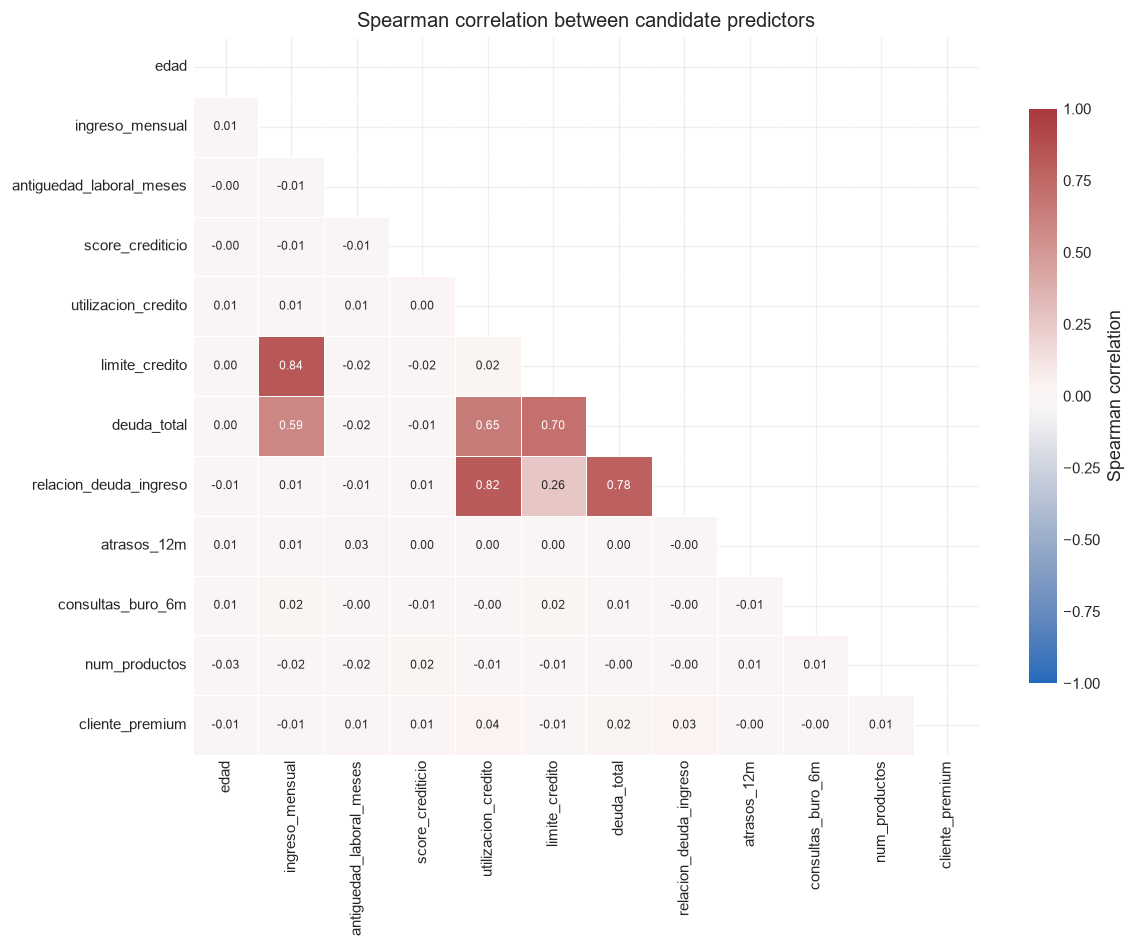

In [33]:
spearman_corr: pd.DataFrame = data[EDA_FEATURES].corr(method="spearman")
upper_mask: np.ndarray = np.triu(np.ones_like(spearman_corr, dtype=bool))

fig, ax = plt.subplots(figsize=FIGURE_SIZE_HEATMAP)
sns.heatmap(
    spearman_corr,
    mask=upper_mask,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Spearman correlation"},
    ax=ax,
)
ax.set_title("Spearman correlation between candidate predictors")
fig.tight_layout()
plt.show()

In [34]:
pearson_corr: np.ndarray = data[EDA_FEATURES].corr().to_numpy()
vif: pd.Series = (
    pd.Series(np.diag(np.linalg.inv(pearson_corr)), index=EDA_FEATURES, name="VIF")
    .sort_values(ascending=False)
)

strong_pairs: pd.DataFrame = (
    spearman_corr.where(np.tril(np.ones_like(spearman_corr, dtype=bool), k=-1))
    .stack()
    .rename("spearman")
    .rename_axis(["feature_a", "feature_b"])
    .reset_index()
    .loc[lambda df: df["spearman"].abs() >= 0.5]
    .sort_values("spearman", key=np.abs, ascending=False)
)

display(vif.to_frame())
display(strong_pairs)

,VIF
limite_credito,8.4610
deuda_total,8.3531
ingreso_mensual,7.1416
relacion_deuda_ingreso,6.9576
utilizacion_credito,4.3538
score_crediticio,1.0034
antiguedad_laboral_meses,1.0033
num_productos,1.0026
atrasos_12m,1.0021
cliente_premium,1.0021


,feature_a,feature_b,spearman
61,limite_credito,ingreso_mensual,0.8417
88,relacion_deuda_ingreso,utilizacion_credito,0.8180
90,relacion_deuda_ingreso,deuda_total,0.7824
77,deuda_total,limite_credito,0.7047
76,deuda_total,utilizacion_credito,0.6501
73,deuda_total,ingreso_mensual,0.5903


**Hallazgo.** Existe un bloque de variables de deuda e ingreso muy correlacionadas: `limite_credito`–`ingreso_mensual` (ρ = 0.84), `relacion_deuda_ingreso`–`utilizacion_credito` (0.82) y `relacion_deuda_ingreso`–`deuda_total` (0.78). Sus VIF van de 4.4 a 8.5; el resto de las variables tiene VIF cercano a 1. En árboles la multicolinealidad no afecta la predicción, pero **reparte la importancia** entre variables equivalentes, lo que se toma en cuenta al interpretar (sección 11).


### 3.7 Mapa de riesgo bivariado


In [35]:
fig = px.scatter(
    data.assign(target_class=data[TARGET].map(CLASS_LABELS)).sort_values(TARGET),
    x="utilizacion_credito",
    y="score_crediticio",
    color="target_class",
    color_discrete_map=CLASS_COLORS,
    opacity=0.55,
    marginal_x="box",
    marginal_y="box",
    hover_data=["consultas_buro_6m", "relacion_deuda_ingreso"],
    title="Credit utilization vs. credit score by class",
    height=650,
)
fig.update_traces(marker_size=4, selector={"type": "scatter"})
fig.update_layout(legend_title_text="Class")
fig.show()

**Hallazgo.** Los incumplidos se acumulan en la zona de utilización alta y score bajo, pero ambas clases se traslapan mucho: no existe una frontera limpia. Esto anticipa un desempeño realista moderado (ROC-AUC cercano a 0.80) y vuelve sospechoso cualquier resultado perfecto.


### 3.8 Detección de valores atípicos


In [36]:
def iqr_outliers(df: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    """
    Count observations beyond Tukey's fences (Q1 - 1.5 IQR, Q3 + 1.5 IQR).
    """

    q1 = df[features].quantile(0.25)
    q3 = df[features].quantile(0.75)
    iqr = q3 - q1
    low_fence = q1 - 1.5 * iqr
    high_fence = q3 + 1.5 * iqr

    n_low = (df[features] < low_fence).sum()
    n_high = (df[features] > high_fence).sum()
    return pd.DataFrame(
        {
            "low_fence": low_fence,
            "high_fence": high_fence,
            "n_low": n_low,
            "n_high": n_high,
            "pct_outliers": (n_low + n_high) / len(df) * 100,
        }
    ).sort_values("pct_outliers", ascending=False)

In [37]:
outlier_report: pd.DataFrame = iqr_outliers(data, CONTINUOUS_FEATURES)
display(outlier_report)

,low_fence,high_fence,n_low,n_high,pct_outliers
deuda_total,"-40,650.3665","121,970.1999",0,273,5.4600
limite_credito,"-47,094.2882","229,061.1640",0,205,4.1000
ingreso_mensual,"-7,222.6658","53,608.1741",0,189,3.7800
relacion_deuda_ingreso,-1.2215,4.8302,0,82,1.6400
score_crediticio,442.2203,914.4801,24,0,0.4800
edad,-3.5000,96.5000,0,0,0.0000
antiguedad_laboral_meses,-185.5000,546.5000,0,0,0.0000
utilizacion_credito,-0.2016,1.1947,0,0,0.0000


In [38]:
monetary_features: list[str] = ["ingreso_mensual", "limite_credito", "deuda_total"]

fig = px.box(
    data[monetary_features]
    .assign(target_class=data[TARGET].map(CLASS_LABELS))
    .melt(id_vars="target_class", var_name="feature", value_name="usd"),
    x="feature",
    y="usd",
    color="target_class",
    color_discrete_map=CLASS_COLORS,
    log_y=True,
    title="Monetary features by class (log scale)",
    height=500,
)
fig.update_layout(legend_title_text="Class", xaxis_title="")
fig.show()

**Hallazgo.** Las variables monetarias tienen entre 3.8% y 5.5% de valores por encima de la cerca de Tukey, pero son valores plausibles (clientes con ingreso o deuda alta), no errores de captura. Se conservan: los árboles particionan por rangos y no son sensibles a valores extremos, y recortarlos eliminaría justamente a parte de los clientes de mayor riesgo.


## 4.0 Auditoría forense del cuaderno original

Se revisó línea por línea el cuaderno del analista junior. Esta sección documenta los errores encontrados (4.1) y reproduce con evidencia los dos más graves: la fuga de información en los datos (4.2) y en el proceso (4.3). Las correcciones se implementan a partir de la sección 5.


### 4.1 Errores conceptuales y metodológicos identificados

| #   | Error en el cuaderno original                                                                                                                                                                                                                       | Impacto técnico                                                                                                                                                        | Impacto de negocio                                                                                                                         | Corrección                                                                                             |
| --- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------ |
| 1   | **Fuga de información en los datos:** se usa `dias_max_atraso_30d_despues`, que se mide _después_ de la evaluación.                                                                                                                                 | Separa las clases perfectamente (correlación 0.90); produce una _accuracy_ de 1.000 artificial.                                                                        | El dato no existe al decidir el crédito: en producción el modelo perdería su variable principal y rendiría muy por debajo de lo prometido. | Se elimina (4.2, 5.1).                                                                                 |
| 2   | **SMOTE antes de la partición train/test.**                                                                                                                                                                                                         | Los clientes sintéticos se interpolan entre vecinos que luego quedan en prueba: información del test se filtra al entrenamiento.                                       | Métricas infladas; la dirección autorizaría un despliegue con una expectativa falsa.                                                       | SMOTE sólo dentro de un `Pipeline` de `imblearn`, aplicado a los pliegues de entrenamiento (5.3, 7.0). |
| 3   | **Conjunto de prueba sintético y balanceado** (50% de incumplidos).                                                                                                                                                                                 | El test no representa la población real (11.7%) e incluye clientes que no existen.                                                                                     | Métricas y utilidad calculadas sobre una cartera irreal con cuatro veces más incumplidos.                                                  | Partición estratificada sobre datos reales; el test conserva 11.7% (5.1).                              |
| 4   | **_Accuracy_ como única métrica.**                                                                                                                                                                                                                  | Con desbalance, aprobar a todos da 88.3% de _accuracy_; no mide ordenamiento ni calibración.                                                                           | No refleja el costo asimétrico: un incumplimiento cuesta cinco veces lo que deja un buen cliente.                                          | PR-AUC, ROC-AUC, Brier y utilidad esperada (6.0).                                                      |
| 5   | **Sin validación cruzada ni ajuste de hiperparámetros**; modelos con valores por defecto.                                                                                                                                                           | Árboles sin restricción memorizan: _accuracy_ de entrenamiento de 0.997 a 1.000 aun sin la fuga, con caída a 0.79–0.89 en prueba.                                      | Modelos inestables que generalizan peor.                                                                                                   | `RandomizedSearchCV` con `StratifiedKFold` de 5 pliegues (7.0).                                        |
| 6   | **Diagnóstico de sobreentrenamiento invertido.** El código dice "verificando que no estén sobreentrenados", pero toma un 1.000 en entrenamiento como éxito.                                                                                         | Se ignora la señal más clara de error.                                                                                                                                 | Se presenta como "prometedor" un resultado que debía detener el proyecto.                                                                  | Brechas train–CV y curva de validación (7.1, 7.2).                                                     |
| 7   | **Umbral optimizado sobre el conjunto de prueba.**                                                                                                                                                                                                  | _Data snooping_: el test deja de ser una estimación independiente.                                                                                                     | Utilidad optimista; incluso en el modelo corregido, elegir el umbral en el test agrega USD 7,333 por 10,000 solicitudes que no son reales. | Umbral elegido por validación cruzada con `TunedThresholdClassifierCV` (8.0, 10.0).                    |
| 8   | **Utilidad económica calculada sobre datos sintéticos.**                                                                                                                                                                                            | Las cifras por 10,000 solicitudes se escalan desde un test con 50% de incumplidos artificiales.                                                                        | Las cifras en dólares presentadas al CEO no tienen sustento.                                                                               | Utilidad sobre clientes reales del test con intervalos bootstrap (9.0, 9.1).                           |
| 9   | **Probabilidades descalibradas.**                                                                                                                                                                                                                   | Entrenar con clases rebalanceadas infla P(incumplimiento): el valor base de SHAP, E[f(X)] = 0.003 en _log-odds_, equivale a una probabilidad de 50%, no al 11.7% real. | El umbral no puede fijarse con la regla de costos 100 / (100 + 500) = 0.167.                                                               | Curva de calibración y Brier; se prefiere un modelo calibrado (9.2, 10.0).                             |
| 10  | **Selección arbitraria del "mejor modelo".**                                                                                                                                                                                                        | Se elige XGBoost sin comparación; los tres "empatan" en 1.000 precisamente por la fuga.                                                                                | Decisión de despliegue sin evidencia.                                                                                                      | Comparación por CV y bootstrap pareado (9.3, 10.0).                                                    |
| 11  | **Matriz de confusión con variables residuales del ciclo.** `modelo` y `nombre` conservan el último valor del `for` (XGBoost) y se usa `predict()` (umbral 0.5), no el umbral optimizado; las etiquetas hablan de "retrasos", no de incumplimiento. | La matriz no corresponde a la política propuesta.                                                                                                                      | Se comunica un desempeño que no es el que se desplegaría.                                                                                  | Matrices del modelo final con umbral 0.5 y óptimo (10.1).                                              |
| 12  | **Interpretabilidad engañosa.** Importancias por impureza (sesgadas hacia variables continuas), SHAP sobre un modelo con fuga y sobre un cliente que puede ser sintético; la interpretación celebra la variable con fuga como "determinante".       | Explicaciones de un modelo que no puede existir en producción.                                                                                                         | Se comunicaría a negocio un factor que no se conoce al decidir.                                                                            | Importancia por permutación y SHAP del modelo corregido, sobre clientes reales (11.0, 11.1).           |


### 4.2 Fuga de información en los datos: `dias_max_atraso_30d_despues`

Según la _Tabla de Variables_, esta variable es el "máximo atraso observado en los **30 días posteriores** a la fecha de evaluación". Al momento de aprobar o revisar el crédito ese dato todavía no existe.


In [39]:
target_corr: pd.DataFrame = (
    data.corr(numeric_only=True)[TARGET]
    .drop(labels=TARGET)
    .sort_values(key=np.abs, ascending=False)
    .to_frame("corr_with_target")
)

display(target_corr)

,corr_with_target
dias_max_atraso_30d_despues,0.8957
utilizacion_credito,0.2315
relacion_deuda_ingreso,0.2229
consultas_buro_6m,0.1959
deuda_total,0.1652
score_crediticio,-0.1520
atrasos_12m,0.0589
limite_credito,0.0332
ingreso_mensual,0.0190
antiguedad_laboral_meses,-0.0158


In [40]:
leakage_by_target: pd.DataFrame = (
    data.groupby(TARGET, observed=True)[LEAKAGE_FEATURE]
    .agg(["min", "max", "mean"])
)

display(leakage_by_target)

,min,max,mean
default_90d,,,
0,0,9,4.4744
1,15,89,52.4659


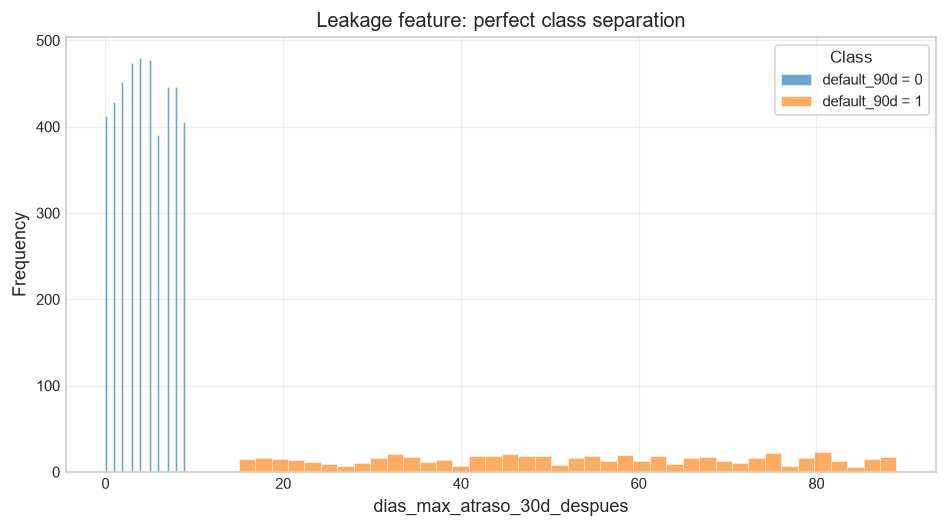

In [41]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE_SINGLE)

for target_value, group in data.groupby(TARGET, observed=True):
    ax.hist(
        group[LEAKAGE_FEATURE],
        bins=40,
        alpha=0.65,
        edgecolor="white",
        linewidth=0.4,
        label=f"{TARGET} = {target_value}",
    )

ax.set(
    xlabel=LEAKAGE_FEATURE,
    ylabel="Frequency",
    title="Leakage feature: perfect class separation",
)
ax.legend(title="Class")
fig.tight_layout()
plt.show()


**Hallazgo: fuga de información confirmada (_target leakage_).**

- Su correlación con el objetivo es 0.90, casi cuatro veces la de la siguiente variable (0.23).
- Los rangos de ambas clases no se traslapan: ningún cliente que pagó supera 9 días de atraso y ningún incumplido tiene menos de 15. Una sola regla ("atraso ≥ 15 días") clasifica a todos correctamente.
- No es un predictor sino parte del propio resultado: un atraso en los 30 días posteriores forma parte de la ventana de 90 días que define el incumplimiento.
- Las demás variables describen el historial o el estado del cliente al momento de la evaluación (por ejemplo, `atrasos_12m` se refiere a los 12 meses _previos_) y ninguna muestra una correlación sospechosa. Sólo esta variable se elimina del modelado.


### 4.3 Fuga en el proceso: reproducción del procedimiento original

Se reproduce exactamente el procedimiento del analista (SMOTE sobre todos los datos → partición 70/30 sin estratificar → modelos por defecto → _accuracy_), con y sin la variable con fuga.


In [42]:
@dataclass(frozen=True)
class SmoteBeforeSplitResult:
    """Metrics from the flawed SMOTE-before-split evaluation."""

    train_accuracy: float
    test_accuracy: float
    test_positive_rate: float


In [43]:
def evaluate_smote_before_split(
    X: pd.DataFrame,
    y: pd.Series,
    estimator: Any,
) -> SmoteBeforeSplitResult:
    """Apply SMOTE before the train/test split, then score with accuracy.

    This procedure is intentionally incorrect: oversampling before splitting
    leaks information from the future test fold into training.
    """
    X_resampled, y_resampled = SMOTE(random_state=RANDOM_STATE).fit_resample(X, y)
    X_train, X_test, y_train, y_test = train_test_split(
        X_resampled,
        y_resampled,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )

    model = clone(estimator).fit(X_train, y_train)

    return SmoteBeforeSplitResult(
        train_accuracy=float(accuracy_score(y_train, model.predict(X_train))),
        test_accuracy=float(accuracy_score(y_test, model.predict(X_test))),
        test_positive_rate=float(np.asarray(y_test).mean()),
    )

In [44]:
X_all: pd.DataFrame = data.drop(columns=[TARGET])
y_all: pd.Series = data[TARGET].astype("int8")

In [45]:
feature_sets: dict[str, pd.DataFrame] = {
    "With leakage feature": X_all,
    "Without leakage feature": X_all.drop(columns=[LEAKAGE_FEATURE]),
}

JUNIOR_MODELS: Final[dict[str, Any]] = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
}

junior_rows: list[dict[str, Any]] = []
for label, X_case in feature_sets.items():
    for model_name, estimator in JUNIOR_MODELS.items():
        result = evaluate_smote_before_split(X_case, y_all, estimator)
        junior_rows.append(
            {
                "features": label,
                "model": model_name,
                "train_accuracy": result.train_accuracy,
                "test_accuracy": result.test_accuracy,
                "test_positive_rate": result.test_positive_rate,
            }
        )

junior_results: pd.DataFrame = pd.DataFrame(junior_rows).set_index(["features", "model"])
display(junior_results)

train_accuracy  test_accuracy  \
features                model                                          
With leakage feature    Decision Tree          1.0000         1.0000   
                        Random Forest          1.0000         1.0000   
                        XGBoost                1.0000         1.0000   
Without leakage feature Decision Tree          1.0000         0.7909   
                        Random Forest          1.0000         0.8849   
                        XGBoost                0.9971         0.8871   

                                       test_positive_rate  
features                model                              
With leakage feature    Decision Tree              0.4991  
                        Random Forest              0.4991  
                        XGBoost                    0.4991  
Without leakage feature Decision Tree              0.4991  
                        Random Forest              0.4991  
                        XGBoost                    0.4991

**Hallazgos.**

- Con la variable con fuga, los tres modelos obtienen 1.000 en entrenamiento y en prueba: el "resultado prometedor" del analista se explica completamente por la fuga.
- Sin ella, la _accuracy_ de prueba cae a 0.79 (árbol), 0.88 (Random Forest) y 0.89 (XGBoost), mientras que la de entrenamiento sigue en 0.997–1.000: evidencia clara de **sobreentrenamiento**.
- La tasa de positivos del test es 49.9% contra 11.7% en la realidad: el conjunto de prueba es sintético y no representa a la cartera. Incluso las cifras sin la fuga siguen infladas por aplicar SMOTE antes de la partición.


## 5.0 Preprocesamiento de datos


### 5.1 Conjunto de modelado y partición estratificada

Se elimina la variable con fuga y los datos se separan 70/30 **antes** de cualquier remuestreo, estratificando por el objetivo. El conjunto de prueba (1,500 clientes reales, 176 incumplidos) sólo se usa al final (sección 9). Dentro del entrenamiento se usa `StratifiedKFold` de 5 pliegues para todas las decisiones.


In [46]:
LEAKY_FEATURES: Final[tuple[str, ...]] = (LEAKAGE_FEATURE,)

In [47]:
X: pd.DataFrame = data.drop(columns=[TARGET, *LEAKY_FEATURES])
y: pd.Series = data[TARGET].astype("int8")

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

In [49]:
N_CV_SPLITS: Final[int] = 5
CV: StratifiedKFold = StratifiedKFold(
    n_splits=N_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print(f"Train: {X_train.shape}, default rate = {y_train.mean():.2%}")
print(f"Test : {X_test.shape}, default rate = {y_test.mean():.2%}")

Train: (3500, 12), default rate = 11.71%
Test : (1500, 12), default rate = 11.73%


### 5.2 Evaluación de conjuntos de variables (redundancia e ingeniería de variables)

¿Conviene eliminar las variables redundantes detectadas en 3.6 o agregar razones financieras nuevas? Se compara con un Random Forest de referencia y validación cruzada **sólo sobre entrenamiento**. Las razones nuevas se calculan por fila (no usan información de otros clientes), por lo que no generan fuga.


In [50]:
def add_engineered_features(X: pd.DataFrame) -> pd.DataFrame:
    """
    Row-wise ratios (stateless, so they cannot leak information across rows).
    """

    return X.assign(
        deuda_sobre_limite=X["deuda_total"] / X["limite_credito"],
        credito_disponible=X["limite_credito"] - X["deuda_total"],
        limite_sobre_ingreso=X["limite_credito"] / X["ingreso_mensual"],
        consultas_por_producto=X["consultas_buro_6m"] / X["num_productos"],
    )

In [51]:
REFERENCE_MODEL: Final[RandomForestClassifier] = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

candidate_feature_sets: dict[str, pd.DataFrame] = {
    "Original (12 features)": X_train,
    "Without relacion_deuda_ingreso": X_train.drop(columns=["relacion_deuda_ingreso"]),
    "Without relacion_deuda_ingreso and deuda_total": X_train.drop(
        columns=["relacion_deuda_ingreso", "deuda_total"]
    ),
    "Original + engineered ratios": add_engineered_features(X_train),
}

In [52]:
feature_set_rows: list[dict[str, Any]] = []
for set_name, X_candidate in candidate_feature_sets.items():
    scores = cross_validate(
        REFERENCE_MODEL,
        X_candidate,
        y_train,
        cv=CV,
        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=-1,
    )
    feature_set_rows.append(
        {
            "feature_set": set_name,
            "n_features": X_candidate.shape[1],
            "pr_auc_cv": scores["test_pr_auc"].mean(),
            "pr_auc_cv_std": scores["test_pr_auc"].std(),
            "roc_auc_cv": scores["test_roc_auc"].mean(),
        }
    )

feature_set_results: pd.DataFrame = pd.DataFrame(feature_set_rows).set_index("feature_set")
display(feature_set_results)

,n_features,pr_auc_cv,pr_auc_cv_std,roc_auc_cv
feature_set,,,,
Original (12 features),12,0.4221,0.0593,0.8046
Without relacion_deuda_ingreso,11,0.4127,0.0550,0.8019
Without relacion_deuda_ingreso and deuda_total,10,0.4117,0.0496,0.8029
Original + engineered ratios,16,0.4101,0.0647,0.7956


In [53]:
fig = px.bar(
    feature_set_results.reset_index(),
    x="pr_auc_cv",
    y="feature_set",
    error_x="pr_auc_cv_std",
    orientation="h",
    text=feature_set_results["pr_auc_cv"].map("{:.3f}".format).to_numpy(),
    title="Reference Random Forest: CV PR-AUC by feature set (+/- 1 std)",
    height=400,
)
fig.update_traces(marker_color=CLASS_COLORS["No default"], textposition="inside", insidetextanchor="start", textfont_color="white")
fig.update_layout(xaxis_title="PR-AUC (5-fold CV, training set)", yaxis_title="")
fig.show()

**Decisión.** El conjunto original de 12 variables obtiene el mejor PR-AUC (0.422); las alternativas quedan entre 0.410 y 0.413. Todas las diferencias son menores a una desviación estándar entre pliegues (0.05–0.06). Ni eliminar redundancias ni agregar razones mejora el modelo, así que se conservan las 12 variables originales: es la opción más simple y auditable.


### 5.3 Pipeline de preprocesamiento


In [54]:
def build_pipeline(estimator: Any) -> Pipeline:
    """
    Imputation -> optional resampling -> model.

    The median imputer is a no-op on the current data (no missing values) but
    protects the production pipeline against incomplete applications. Being
    fitted inside the pipeline, it only learns medians from training folds.
    Tree models are invariant to monotone transformations, so no scaling,
    log transforms or outlier clipping are applied.
    """

    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median").set_output(transform="pandas")),
            ("sampler", "passthrough"),
            ("model", estimator),
        ]
    )

**Decisiones de preprocesamiento.**

- **Imputación por mediana dentro del pipeline:** hoy no hay faltantes, pero en producción llegarán solicitudes incompletas. Al estar dentro del pipeline, las medianas se aprenden sólo de los pliegues de entrenamiento.
- **Remuestreo como hiperparámetro** (`passthrough` o SMOTE): si SMOTE ayuda, la búsqueda lo elige, y siempre se aplica únicamente a los datos de entrenamiento de cada pliegue.
- **Sin escalamiento, transformaciones logarítmicas ni recorte de atípicos:** los árboles son invariantes a transformaciones monótonas y robustos a valores extremos.
- **Sin codificación categórica:** `cliente_premium` ya es 0/1 y el resto de las variables son numéricas.


## 6.0 Métricas de evaluación y función de utilidad del negocio

**¿Por qué no _accuracy_?** Con 11.7% de incumplidos, aprobar a todos ya da 88.3% de _accuracy_. Además, la _accuracy_ trata igual los dos errores, cuando aprobar a un incumplido cuesta USD 500 y rechazar a un buen cliente sólo deja de ganar USD 100.

**Métricas elegidas:**

- **PR-AUC (_average precision_)**, métrica principal para elegir hiperparámetros: se enfoca en la clase minoritaria y su línea base es la prevalencia (0.117), no 0.5, así que refleja bien el desempeño bajo desbalance.
- **ROC-AUC:** capacidad de ordenar a los clientes por riesgo, independiente del umbral; es el estándar de la industria (AUC/Gini).
- **Brier score:** mide la calibración. Es necesaria porque el umbral económico supone que las probabilidades son reales.
- **Utilidad esperada (USD por 10,000 solicitudes):** la métrica de negocio, con +USD 100 por buen cliente aprobado, −USD 500 por incumplido aprobado y 0 por solicitud rechazada. Es la que define el umbral y la elección final.

Las métricas de umbral (_recall_, precisión) se reportan en la tabla de sensibilidad (10.0). F1 no se usa para decidir porque pondera igual dos errores con costos muy distintos.


In [55]:
@dataclass(frozen=True)
class BusinessCosts:
    """
    Payoff for approving a customer under the credit policy.
    """

    profit_on_good: float = 100.0  # approved customer who pays
    loss_on_default: float = -500.0  # approved customer who defaults

In [56]:
BUSINESS_COSTS: Final[BusinessCosts] = BusinessCosts()

In [57]:
def total_utility(
    y_true: np.ndarray | pd.Series,
    y_pred_default: np.ndarray | pd.Series,
    costs: BusinessCosts = BUSINESS_COSTS,
) -> float:
    """
    Total payoff when predicting default (1 = reject, 0 = approve).
    """
    
    y_true_arr = np.asarray(y_true)
    approved = np.asarray(y_pred_default) == 0

    n_good = int(np.sum(approved & (y_true_arr == 0)))
    n_bad = int(np.sum(approved & (y_true_arr == 1)))
    return float(n_good * costs.profit_on_good + n_bad * costs.loss_on_default)


In [58]:
def utility_per_application(
    y_true: np.ndarray | pd.Series,
    y_pred_default: np.ndarray | pd.Series,
    costs: BusinessCosts = BUSINESS_COSTS,
) -> float:
    """
    Average payoff per application.
    """
    
    return total_utility(y_true, y_pred_default, costs) / len(y_true)

In [59]:
def utility_per_10k(
    y_true: np.ndarray | pd.Series,
    y_pred_default: np.ndarray | pd.Series,
    costs: BusinessCosts = BUSINESS_COSTS,
) -> float:
    """
    Scaled payoff per 10,000 applications.
    """
    
    return utility_per_application(y_true, y_pred_default, costs) * 10_000

In [60]:
def predict_with_threshold(
    y_prob: np.ndarray | pd.Series,
    threshold: float,
) -> np.ndarray:
    """
    Predict default (1 = reject) when P(default) >= threshold.
    """
    
    return (np.asarray(y_prob) >= threshold).astype(int)

In [61]:
profit_scorer = make_scorer(utility_per_application)

In [62]:
baseline_utility_10k: float = utility_per_10k(y_test, np.zeros_like(y_test))
print(
    f"Baseline 'approve all' (test): ${baseline_utility_10k:,.0f} "
    f"per 10,000 applications"
)

Baseline 'approve all' (test): $296,000 per 10,000 applications


**Referencia.** Aprobar a todos los solicitantes deja USD 296,000 por cada 10,000 solicitudes en el test (88.3% pagan × USD 100 − 11.7% incumplen × USD 500). Cualquier modelo debe superar este valor para justificar su uso.


## 7.0 Búsqueda de hiperparámetros con validación cruzada estratificada

Para cada familia de modelos se prueban 40 combinaciones con `RandomizedSearchCV` y 5 pliegues estratificados, optimizando PR-AUC. El espacio incluye regularización (profundidad, hojas mínimas, poda, `learning_rate`, submuestreo) y tres formas de tratar el desbalance: ninguna, SMOTE dentro del pipeline o pesos de clase (`class_weight` / `scale_pos_weight`).


In [63]:
SAMPLER_OPTIONS: Final[list[Any]] = [
    "passthrough",
    SMOTE(random_state=RANDOM_STATE),
]

n_negative, n_positive = np.bincount(y_train)
scale_pos_weight: float = float(n_negative / n_positive)

In [64]:
MODEL_CONFIGS: dict[str, tuple[Any, dict[str, Any]]] = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "sampler": SAMPLER_OPTIONS,
            "model__max_depth": randint(2, 11),
            "model__min_samples_leaf": randint(5, 101),
            "model__ccp_alpha": loguniform(1e-5, 1e-2),
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "sampler": SAMPLER_OPTIONS,
            "model__n_estimators": randint(200, 601),
            "model__max_depth": [4, 6, 8, 10, 12, None],
            "model__min_samples_leaf": randint(1, 31),
            "model__max_features": ["sqrt", 0.5, 0.8],
            "model__class_weight": [None, "balanced_subsample"],
        },
    ),
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
        ),
        {
            "sampler": SAMPLER_OPTIONS,
            "model__n_estimators": randint(100, 801),
            "model__learning_rate": loguniform(0.01, 0.2),
            "model__max_depth": randint(2, 7),
            "model__min_child_weight": randint(1, 11),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.6, 0.4),
            "model__reg_lambda": loguniform(0.1, 10),
            "model__scale_pos_weight": [1, scale_pos_weight],
        },
    ),
}

In [65]:
N_SEARCH_ITER: Final[int] = 40
REFIT_METRIC: Final[str] = "pr_auc"

SCORING: Final[dict[str, str]] = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "brier": "neg_brier_score",
}


In [66]:
searches: dict[str, RandomizedSearchCV] = {}

for model_name, (estimator, param_distributions) in MODEL_CONFIGS.items():
    pipeline = build_pipeline(estimator)
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=N_SEARCH_ITER,
        scoring=SCORING,
        refit=REFIT_METRIC,
        cv=CV,
        return_train_score=True,  # diagnose overfitting
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[model_name] = search
    print(f"{model_name}: PR-AUC CV = {search.best_score_:.4f}")
    print(f"   best params: {search.best_params_}")


Decision Tree: PR-AUC CV = 0.3620
   best params: {'model__ccp_alpha': np.float64(0.0010779345294533718), 'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 13, 'sampler': 'passthrough'}
Random Forest: PR-AUC CV = 0.4286
   best params: {'model__class_weight': None, 'model__max_depth': 4, 'model__max_features': 0.5, 'model__min_samples_leaf': 27, 'model__n_estimators': 314, 'sampler': 'passthrough'}
XGBoost: PR-AUC CV = 0.4241
   best params: {'model__colsample_bytree': np.float64(0.6811319943644287), 'model__learning_rate': np.float64(0.01403361431085533), 'model__max_depth': 3, 'model__min_child_weight': 6, 'model__n_estimators': 151, 'model__reg_lambda': np.float64(0.7003577668929769), 'model__scale_pos_weight': 7.536585365853658, 'model__subsample': np.float64(0.8546905773122786), 'sampler': 'passthrough'}


**Hallazgo.** Ningún modelo eligió SMOTE: con estos datos, sintetizar incumplidos no mejora el PR-AUC. Random Forest (0.429) y XGBoost (0.424) superan con claridad al árbol de decisión (0.362). Los mejores ensambles son poco profundos (Random Forest con `max_depth=4`, XGBoost con `max_depth=3`): la relación es relativamente simple y más complejidad sólo memoriza ruido.


### 7.1 Resumen de validación cruzada


In [67]:
def summarize_cv(search: RandomizedSearchCV) -> dict[str, float]:
    """
    Extract train/CV metrics for the best RandomizedSearchCV candidate.
    """
    
    results = search.cv_results_
    best_idx = search.best_index_

    summary: dict[str, float] = {}
    for metric_name in SCORING:
        summary[f"{metric_name}_train"] = float(results[f"mean_train_{metric_name}"][best_idx])
        summary[f"{metric_name}_cv"] = float(results[f"mean_test_{metric_name}"][best_idx])
        summary[f"{metric_name}_cv_std"] = float(results[f"std_test_{metric_name}"][best_idx])

    summary["pr_auc_gap"] = summary["pr_auc_train"] - summary["pr_auc_cv"]
    return summary

In [68]:
cv_summary: pd.DataFrame = pd.DataFrame(
    {model_name: summarize_cv(search) for model_name, search in searches.items()}
).T

display(cv_summary)

,pr_auc_train,pr_auc_cv,pr_auc_cv_std,roc_auc_train,roc_auc_cv,roc_auc_cv_std,brier_train,brier_cv,brier_cv_std,pr_auc_gap
Decision Tree,0.4612,0.3620,0.0296,0.8031,0.7640,0.0367,-0.0781,-0.0887,0.0038,0.0992
Random Forest,0.5074,0.4286,0.0595,0.8445,0.8026,0.0239,-0.0797,-0.0858,0.0045,0.0788
XGBoost,0.5327,0.4241,0.0573,0.8606,0.8053,0.0264,-0.1608,-0.1697,0.0036,0.1086


### 7.2 Diagnóstico de sub y sobreentrenamiento


In [69]:
unconstrained_tree_cv: dict[str, np.ndarray] = cross_validate(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train,
    y_train,
    cv=CV,
    scoring=SCORING,
    return_train_score=True,
)

print(
    "Unconstrained decision tree: "
    f"PR-AUC train={unconstrained_tree_cv['train_pr_auc'].mean():.3f} | "
    f"CV={unconstrained_tree_cv['test_pr_auc'].mean():.3f}"
)

Unconstrained decision tree: PR-AUC train=1.000 | CV=0.168


In [70]:
max_depths: np.ndarray = np.arange(1, 21)
train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=1),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=max_depths,
    cv=CV,
    scoring="average_precision",
    n_jobs=-1,
)

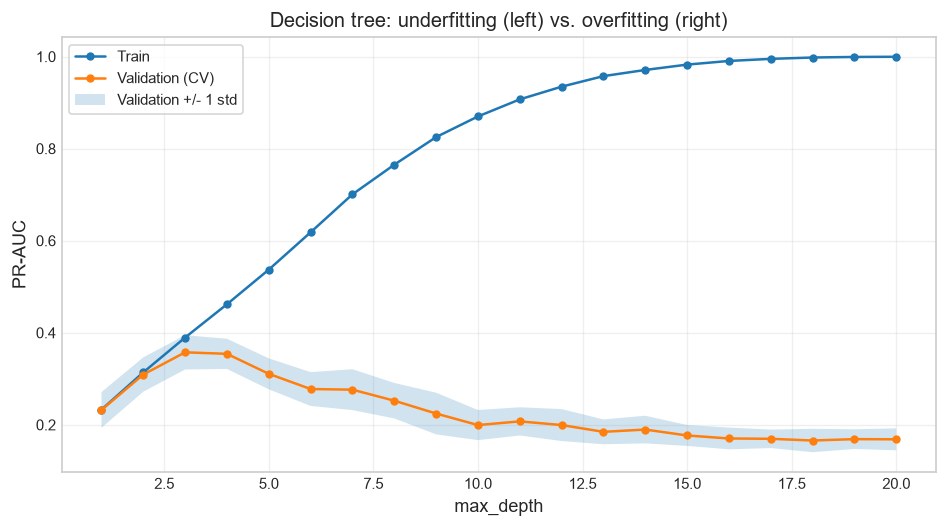

In [71]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE_SINGLE)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

ax.plot(max_depths, train_mean, marker="o", markersize=4, label="Train")
ax.plot(max_depths, val_mean, marker="o", markersize=4, label="Validation (CV)")
ax.fill_between(
    max_depths,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2,
    label="Validation +/- 1 std",
)

ax.set(
    xlabel="max_depth",
    ylabel="PR-AUC",
    title="Decision tree: underfitting (left) vs. overfitting (right)",
)
ax.legend(loc="best")
fig.tight_layout()
plt.show()

In [72]:
best_depth_idx: int = int(np.argmax(val_mean))

for label, idx in [
    ("Shallowest (max_depth=1)", 0),
    (f"Best CV (max_depth={max_depths[best_depth_idx]})", best_depth_idx),
    (f"Deepest (max_depth={max_depths[-1]})", len(max_depths) - 1),
]:
    print(
        f"{label:<26}: PR-AUC train = {train_mean[idx]:.3f} | "
        f"CV = {val_mean[idx]:.3f} | gap = {train_mean[idx] - val_mean[idx]:.3f}"
    )

Shallowest (max_depth=1)  : PR-AUC train = 0.233 | CV = 0.232 | gap = 0.001
Best CV (max_depth=3)     : PR-AUC train = 0.390 | CV = 0.358 | gap = 0.032
Deepest (max_depth=20)    : PR-AUC train = 1.000 | CV = 0.169 | gap = 0.831


**Evidencia de sub y sobreentrenamiento (respecto a PR-AUC).**

- **Sobreentrenamiento severo en el enfoque original:** un árbol sin restricciones, la configuración por defecto que usó el analista, llega a PR-AUC de 1.000 en entrenamiento y 0.168 en validación. Con `max_depth=20` la brecha es de 0.83.
- **Subentrenamiento:** con `max_depth=1` el árbol queda en 0.23 tanto en entrenamiento como en validación: no hay brecha, pero tampoco capacidad.
- **Punto de equilibrio:** profundidad 3 (entrenamiento 0.390, validación 0.358, brecha de 0.03).
- **Modelos ajustados:** las brechas train–CV de PR-AUC son moderadas (árbol 0.099, Random Forest 0.079, XGBoost 0.109) y la variación entre pliegues es de 0.03 a 0.06. Random Forest tiene la menor brecha. En prueba, el PR-AUC (0.327 / 0.383 / 0.409) es consistente con la validación cruzada dentro de la variabilidad esperada para sólo 176 incumplidos.

**Estrategia de validación.** Partición estratificada 70/30 con un conjunto de prueba que no se toca hasta el final; dentro del entrenamiento, `StratifiedKFold(5)` para hiperparámetros y umbral. Limitación: hiperparámetros y umbral se eligen con los mismos pliegues, lo que puede sesgar ligeramente al alza la utilidad de CV. Una validación anidada o, mejor aún, una validación fuera de tiempo (_out-of-time_) sería el siguiente paso antes de producción; el dataset no incluye fechas.


## 8.0 Optimización del umbral de decisión

En lugar de usar 0.5, el umbral se elige maximizando la utilidad esperada con `TunedThresholdClassifierCV` (validación cruzada sobre entrenamiento). Con probabilidades calibradas, la teoría de decisión da el umbral óptimo de forma directa: rechazar si P(incumplimiento) > 100 / (100 + 500) ≈ 0.167.


In [73]:
THRESHOLDS: np.ndarray = np.round(np.arange(0.01, 1.00, 0.01), 2)

In [74]:
threshold_models: dict[str, TunedThresholdClassifierCV] = {}
for model_name, search in searches.items():
    tuned = TunedThresholdClassifierCV(
        search.best_estimator_,
        scoring=profit_scorer,
        thresholds=THRESHOLDS,
        cv=CV,
        store_cv_results=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ).fit(X_train, y_train)

    threshold_models[model_name] = tuned
    print(
        f"{model_name:<18} optimal threshold (CV) = {tuned.best_threshold_:.2f} | "
        f"utility CV = ${tuned.best_score_ * 10_000:,.0f} per 10k applications"
    )

Decision Tree      optimal threshold (CV) = 0.12 | utility CV = $501,714 per 10k applications
Random Forest      optimal threshold (CV) = 0.15 | utility CV = $511,143 per 10k applications
XGBoost            optimal threshold (CV) = 0.55 | utility CV = $509,429 per 10k applications


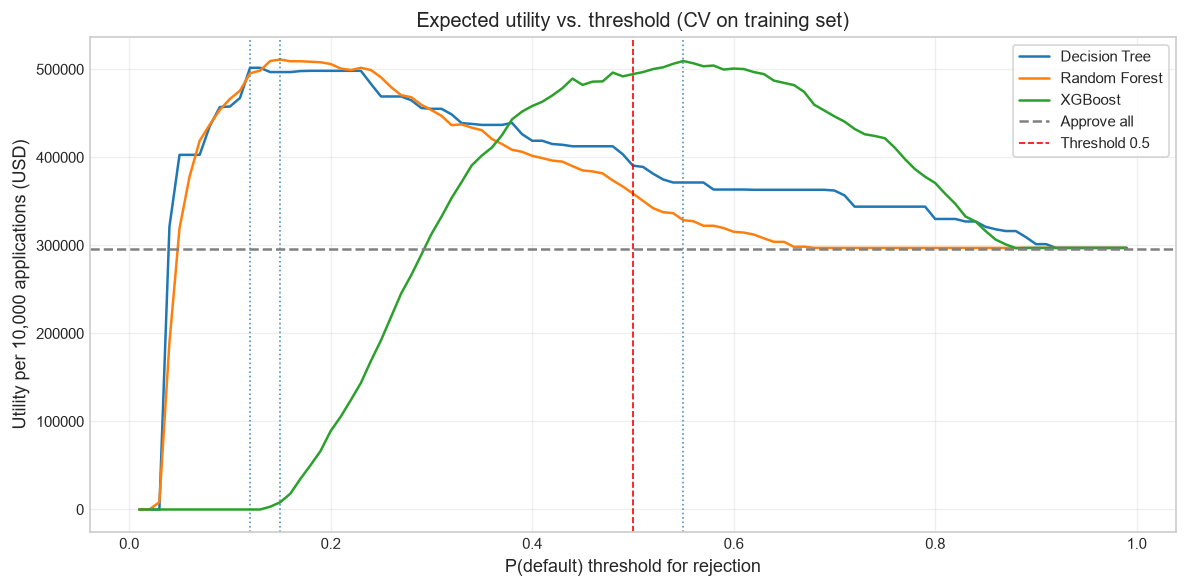

In [75]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE_WIDE)
for model_name, tuned in threshold_models.items():
    ax.plot(
        tuned.cv_results_["thresholds"],
        tuned.cv_results_["scores"] * 10_000,
        label=model_name,
    )

    ax.axvline(tuned.best_threshold_, ls=":", lw=1, alpha=0.8)

ax.axhline(baseline_utility_10k, color="gray", ls="--", label="Approve all")
ax.axvline(0.5, color="red", ls="--", lw=1, label="Threshold 0.5")
ax.set(
    xlabel="P(default) threshold for rejection",
    ylabel="Utility per 10,000 applications (USD)",
    title="Expected utility vs. threshold (CV on training set)",
)

ax.legend(loc="best")
fig.tight_layout()
plt.show()


**Hallazgos.**

- Random Forest y el árbol alcanzan su máximo en umbrales bajos (0.15 y 0.12), muy cerca del valor teórico de 0.167, porque sus probabilidades están calibradas.
- XGBoost alcanza su máximo en 0.55: `scale_pos_weight` infla sus probabilidades, así que su umbral no se puede leer como una probabilidad real.
- La curva de Random Forest tiene una meseta amplia entre 0.12 y 0.25 aproximadamente: la utilidad es robusta a pequeños errores en el umbral, una propiedad valiosa en producción.
- Con 0.5, Random Forest y el árbol quedan muy por debajo de su óptimo. El umbral por defecto no es neutral: equivale a suponer que un incumplimiento cuesta lo mismo que lo que deja un buen cliente.


## 9.0 Evaluación final en el conjunto de prueba

El conjunto de prueba (1,500 clientes reales nunca vistos) se usa una sola vez, con los umbrales ya fijados por validación cruzada.


In [76]:
rows: list[dict[str, Any]] = []
y_probs: dict[str, np.ndarray] = {}

for model_name, tuned in threshold_models.items():
    probs = tuned.estimator_.predict_proba(X_test)[:, 1]
    y_probs[model_name] = probs
    optimal_threshold = float(tuned.best_threshold_)

    rows.append(
        {
            "model": model_name,
            "roc_auc": roc_auc_score(y_test, probs),
            "pr_auc": average_precision_score(y_test, probs),
            "brier": brier_score_loss(y_test, probs),
            "optimal_threshold": optimal_threshold,
            "utility_10k_t05": utility_per_10k(
                y_test, predict_with_threshold(probs, 0.5)
            ),
            "utility_10k_topt": utility_per_10k(
                y_test, predict_with_threshold(probs, optimal_threshold)
            ),
            "approval_rate_topt": 1.0
            - float(predict_with_threshold(probs, optimal_threshold).mean()),
        }
    )

In [77]:
results: pd.DataFrame = pd.DataFrame(rows).set_index("model")
results["vs_approve_all_10k"] = results["utility_10k_topt"] - baseline_utility_10k

print(
    "Default prevalence in test "
    f"(PR-AUC of a random model): {y_test.mean():.4f}"
)

display(results)

Default prevalence in test (PR-AUC of a random model): 0.1173


,roc_auc,pr_auc,brier,optimal_threshold,utility_10k_t05,utility_10k_topt,approval_rate_topt,vs_approve_all_10k
model,,,,,,,,
Decision Tree,0.7523,0.3274,0.0908,0.1200,"368,666.6667","467,333.3333",0.7073,"171,333.3333"
Random Forest,0.7987,0.3832,0.0866,0.1500,"348,000.0000","508,666.6667",0.7807,"212,666.6667"
XGBoost,0.8080,0.4094,0.1734,0.5500,"509,333.3333","504,666.6667",0.7807,"208,666.6667"


**Hallazgos.**

- **Ordenamiento:** XGBoost (ROC-AUC 0.808, PR-AUC 0.409) ≥ Random Forest (0.799, 0.383) > árbol (0.752, 0.327). Todos superan la línea base de PR-AUC (0.117).
- **Utilidad con su umbral óptimo:** Random Forest USD 508,667, XGBoost USD 504,667 y árbol USD 467,333 por cada 10,000 solicitudes, contra USD 296,000 de aprobar a todos (+72% con Random Forest).
- **Calibración (Brier):** Random Forest 0.087 y árbol 0.091 contra 0.173 de XGBoost; se confirma la descalibración de XGBoost.


### 9.1 Incertidumbre de la utilidad (bootstrap)


In [78]:
def bootstrap_utility(
    y_true: np.ndarray | pd.Series,
    y_pred: np.ndarray | pd.Series,
    n_boot: int = 2_000,
    seed: int = RANDOM_STATE,
) -> np.ndarray:
    """
    Bootstrap distribution of utility per 10k applications.
    """
    
    rng = np.random.default_rng(seed)
    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)
    indices = rng.integers(0, len(y_true_arr), size=(n_boot, len(y_true_arr)))
    return np.array(
        [utility_per_10k(y_true_arr[i], y_pred_arr[i]) for i in indices]
    )

In [79]:
confidence_intervals: dict[str, dict[str, float]] = {}
for model_name, tuned in threshold_models.items():
    preds = predict_with_threshold(y_probs[model_name], tuned.best_threshold_)
    dist = bootstrap_utility(y_test, preds)
    confidence_intervals[model_name] = {
        "mean": float(dist.mean()),
        "ci95_low": float(np.percentile(dist, 2.5)),
        "ci95_high": float(np.percentile(dist, 97.5)),
    }

display(pd.DataFrame(confidence_intervals).T.round(0))

,mean,ci95_low,ci95_high
Decision Tree,"467,214.0000","408,667.0000","527,333.0000"
Random Forest,"507,974.0000","443,333.0000","570,667.0000"
XGBoost,"504,104.0000","439,333.0000","566,000.0000"


**Hallazgo.** Los intervalos de 95% de Random Forest (USD 443k–571k) y XGBoost (USD 439k–566k) se traslapan casi por completo; el del árbol (USD 409k–527k) queda más abajo. Como estos intervalos no son pareados, la comparación formal se hace en 9.3.


### 9.2 Curvas ROC, Precisión-Recall y calibración


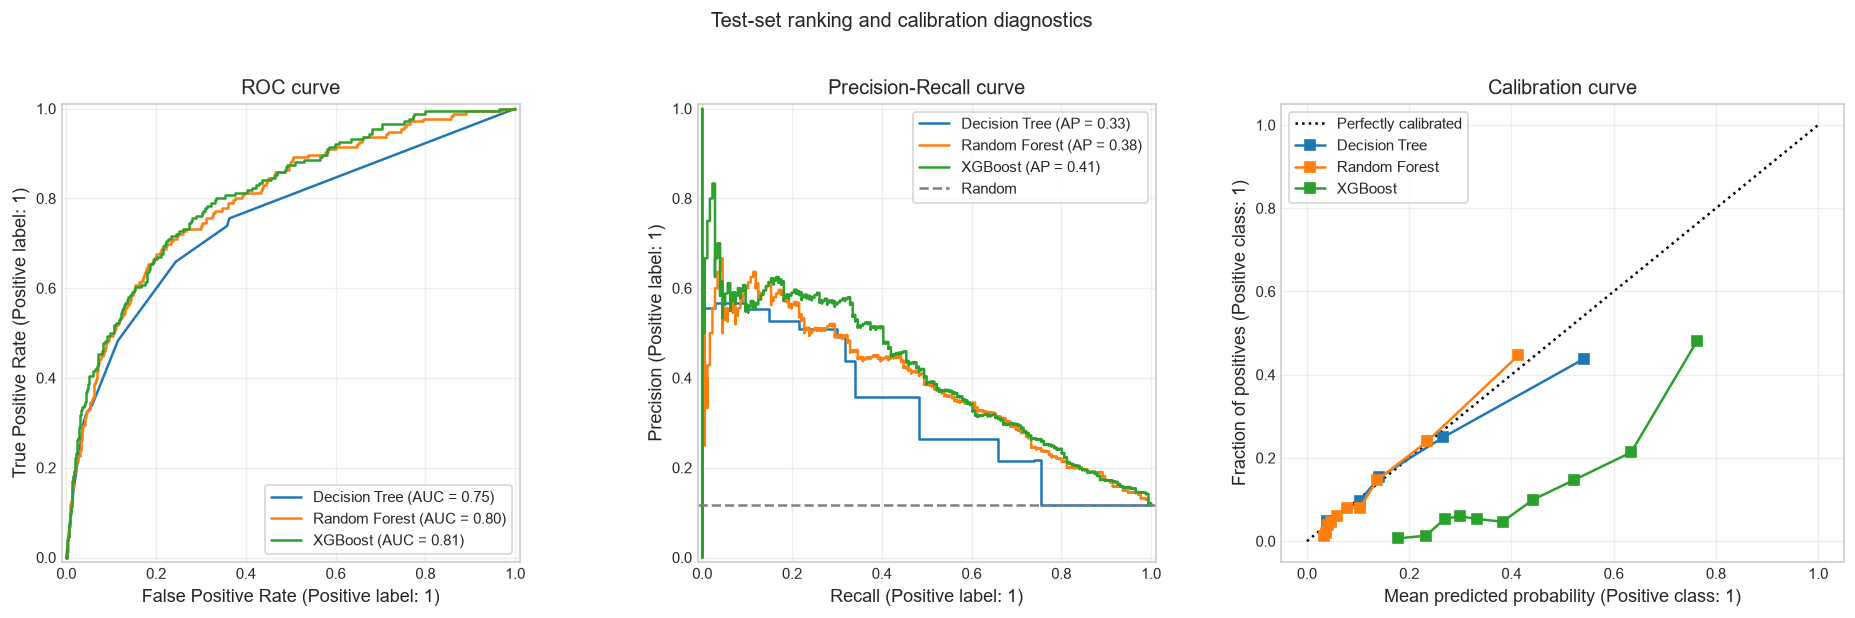

In [80]:
fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE_PANEL)

for model_name, probs in y_probs.items():
    RocCurveDisplay.from_predictions(y_test, probs, name=model_name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, probs, name=model_name, ax=axes[1]
    )
    CalibrationDisplay.from_predictions(
        y_test,
        probs,
        n_bins=10,
        strategy="quantile",
        name=model_name,
        ax=axes[2],
    )

axes[1].axhline(float(y_test.mean()), color="gray", ls="--", label="Random")
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-Recall curve")
axes[2].set_title("Calibration curve")

for ax in axes:
    ax.legend(loc="best")

fig.suptitle("Test-set ranking and calibration diagnostics", y=1.02)
fig.tight_layout()
plt.show()


**Hallazgo.** Las curvas ROC y PR confirman que Random Forest y XGBoost ordenan de forma muy parecida y mejor que el árbol. La diferencia clave está en la calibración: Random Forest y el árbol siguen la diagonal (una probabilidad estimada de 20% corresponde a cerca de 20% de incumplimientos reales), mientras que XGBoost sobreestima de forma sistemática (predice alrededor de 40% donde ocurre cerca de 5%).


### 9.3 Comparación pareada de modelos

Las diferencias se miden de forma pareada: los mismos pliegues de CV y los mismos remuestreos bootstrap del test para todos los modelos. Así se elimina el ruido común y se puede saber si una diferencia es real o producto del azar.


In [81]:
cv_fold_scores: pd.DataFrame = pd.DataFrame(
    {
        model_name: [
            search.cv_results_[f"split{fold}_test_pr_auc"][search.best_index_]
            for fold in range(N_CV_SPLITS)
        ]
        for model_name, search in searches.items()
    },
    index=pd.RangeIndex(1, N_CV_SPLITS + 1, name="fold"),
)

display(cv_fold_scores)

,Decision Tree,Random Forest,XGBoost
fold,,,
1,0.3039,0.3142,0.3116
2,0.3791,0.4828,0.4465
3,0.3669,0.4322,0.4369
4,0.3750,0.4529,0.4554
5,0.3850,0.4609,0.4701


In [82]:
fold_differences: pd.DataFrame = pd.DataFrame(
    [
        {
            "comparison": f"{model_a} - {model_b}",
            "mean_diff": (cv_fold_scores[model_a] - cv_fold_scores[model_b]).mean(),
            "std_diff": (cv_fold_scores[model_a] - cv_fold_scores[model_b]).std(),
            "folds_won_by_first": int((cv_fold_scores[model_a] > cv_fold_scores[model_b]).sum()),
        }
        for model_a, model_b in combinations(cv_fold_scores.columns, 2)
    ]
).set_index("comparison")

display(fold_differences)

fig = px.line(
    cv_fold_scores.reset_index().melt(id_vars="fold", var_name="model", value_name="pr_auc"),
    x="fold",
    y="pr_auc",
    color="model",
    markers=True,
    title="PR-AUC per CV fold (same folds for every model)",
    height=420,
)
fig.update_xaxes(dtick=1)
fig.update_layout(yaxis_title="PR-AUC (validation fold)", legend_title_text="Model")
fig.show()

,mean_diff,std_diff,folds_won_by_first
comparison,,,
Decision Tree - Random Forest,-0.0666,0.0345,0
Decision Tree - XGBoost,-0.0621,0.0313,0
Random Forest - XGBoost,0.0045,0.0183,2


In [83]:
def paired_bootstrap(
    y_true: np.ndarray | pd.Series,
    probs_by_model: dict[str, np.ndarray],
    thresholds_by_model: dict[str, float],
    n_boot: int = 2_000,
    seed: int = RANDOM_STATE,
) -> pd.DataFrame:
    """
    Score every model on the same bootstrap resamples of the test set.

    Sharing the resamples makes the model differences paired: the noise from
    which clients happen to be drawn cancels out, leaving the model effect.
    """

    rng = np.random.default_rng(seed)
    y_true_arr = np.asarray(y_true)
    indices = rng.integers(0, len(y_true_arr), size=(n_boot, len(y_true_arr)))

    rows: list[dict[str, Any]] = []
    for resample, idx in enumerate(indices):
        y_boot = y_true_arr[idx]
        for model_name, probs in probs_by_model.items():
            probs_boot = probs[idx]
            rows.append(
                {
                    "resample": resample,
                    "model": model_name,
                    "utility_10k": utility_per_10k(
                        y_boot,
                        predict_with_threshold(probs_boot, thresholds_by_model[model_name]),
                    ),
                    "pr_auc": average_precision_score(y_boot, probs_boot),
                    "roc_auc": roc_auc_score(y_boot, probs_boot),
                    "brier": brier_score_loss(y_boot, probs_boot),
                }
            )

    return pd.DataFrame(rows)

In [84]:
COMPARISON_METRICS: Final[dict[str, bool]] = {  # metric -> higher is better
    "utility_10k": True,
    "pr_auc": True,
    "roc_auc": True,
    "brier": False,
}

optimal_thresholds: dict[str, float] = {
    model_name: float(tuned.best_threshold_)
    for model_name, tuned in threshold_models.items()
}

bootstrap_metrics: pd.DataFrame = paired_bootstrap(y_test, y_probs, optimal_thresholds)

In [85]:
def pairwise_differences(
    boot: pd.DataFrame,
    metrics: dict[str, bool] = COMPARISON_METRICS,
) -> pd.DataFrame:
    """
    Paired bootstrap difference (first model minus second) for every pair of
    models, with its 95% percentile interval and the probability that the
    first model is better.
    """

    rows: list[dict[str, Any]] = []
    for metric, higher_is_better in metrics.items():
        wide = boot.pivot(index="resample", columns="model", values=metric)
        for model_a, model_b in combinations(wide.columns, 2):
            diff = wide[model_a] - wide[model_b]
            ci_low, ci_high = diff.quantile([0.025, 0.975])
            first_better = diff > 0 if higher_is_better else diff < 0
            rows.append(
                {
                    "metric": metric,
                    "comparison": f"{model_a} - {model_b}",
                    "mean_diff": diff.mean(),
                    "ci95_low": ci_low,
                    "ci95_high": ci_high,
                    "p_first_better": first_better.mean(),
                    "significant": not (ci_low <= 0 <= ci_high),
                }
            )

    return pd.DataFrame(rows).set_index(["metric", "comparison"])

In [86]:
paired_differences: pd.DataFrame = pairwise_differences(bootstrap_metrics)
display(paired_differences)

mean_diff     ci95_low  \
metric      comparison                                                
utility_10k Decision Tree - Random Forest -40,760.3333 -77,333.3333   
            Decision Tree - XGBoost       -36,890.6667 -71,333.3333   
            Random Forest - XGBoost         3,869.6667 -19,333.3333   
pr_auc      Decision Tree - Random Forest      -0.0581      -0.1027   
            Decision Tree - XGBoost            -0.0832      -0.1314   
            Random Forest - XGBoost            -0.0251      -0.0466   
roc_auc     Decision Tree - Random Forest      -0.0463      -0.0668   
            Decision Tree - XGBoost            -0.0555      -0.0793   
            Random Forest - XGBoost            -0.0092      -0.0196   
brier       Decision Tree - Random Forest       0.0042       0.0007   
            Decision Tree - XGBoost            -0.0825      -0.0935   
            Random Forest - XGBoost            -0.0867      -0.0971   

                                            ci95_high  p_first_better  \
metric      comparison                                                  
utility_10k Decision Tree - Random Forest -4,000.0000          0.0115   
            Decision Tree - XGBoost       -1,333.3333          0.0185   
            Random Forest - XGBoost       27,333.3333          0.6115   
pr_auc      Decision Tree - Random Forest     -0.0158          0.0020   
            Decision Tree - XGBoost           -0.0375          0.0000   
            Random Forest - XGBoost           -0.0051          0.0075   
roc_auc     Decision Tree - Random Forest     -0.0263          0.0000   
            Decision Tree - XGBoost           -0.0321          0.0000   
            Random Forest - XGBoost            0.0019          0.0520   
brier       Decision Tree - Random Forest      0.0079          0.0125   
            Decision Tree - XGBoost           -0.0715          1.0000   
            Random Forest - XGBoost           -0.0763          1.0000   

                                           significant  
metric      comparison                                  
utility_10k Decision Tree - Random Forest         True  
            Decision Tree - XGBoost               True  
            Random Forest - XGBoost              False  
pr_auc      Decision Tree - Random Forest         True  
            Decision Tree - XGBoost               True  
            Random Forest - XGBoost               True  
roc_auc     Decision Tree - Random Forest         True  
            Decision Tree - XGBoost               True  
            Random Forest - XGBoost              False  
brier       Decision Tree - Random Forest         True  
            Decision Tree - XGBoost               True  
            Random Forest - XGBoost               True

In [87]:
fig = make_subplots(
    rows=1,
    cols=len(COMPARISON_METRICS),
    subplot_titles=[
        f"{metric} {'(higher = better)' if higher else '(lower = better)'}"
        for metric, higher in COMPARISON_METRICS.items()
    ],
    shared_yaxes=True,
    horizontal_spacing=0.05,
)
for position, metric in enumerate(COMPARISON_METRICS, start=1):
    diffs = paired_differences.loc[metric]
    fig.add_trace(
        go.Scatter(
            x=diffs["mean_diff"],
            y=diffs.index,
            mode="markers",
            marker={
                "size": 10,
                "color": np.where(diffs["significant"], CLASS_COLORS["Default"], "gray"),
            },
            error_x={
                "type": "data",
                "symmetric": False,
                "array": diffs["ci95_high"] - diffs["mean_diff"],
                "arrayminus": diffs["mean_diff"] - diffs["ci95_low"],
            },
            hovertemplate="%{y}: %{x:.4f}<extra></extra>",
            showlegend=False,
        ),
        row=1,
        col=position,
    )
    fig.add_vline(x=0, line_dash="dash", line_color="gray", row=1, col=position)

fig.update_layout(
    title="Paired bootstrap differences on the test set (95% CI; orange = excludes 0)",
    height=420,
)
fig.update_annotations(font_size=11)
fig.show()

In [88]:
scorecard: pd.DataFrame = pd.DataFrame(
    {
        "utility_cv_10k": {
            name: tuned.best_score_ * 10_000 for name, tuned in threshold_models.items()
        },
        "utility_test_10k": results["utility_10k_topt"],
        "pr_auc_cv": cv_summary["pr_auc_cv"],
        "pr_auc_test": results["pr_auc"],
        "pr_auc_train_cv_gap": cv_summary["pr_auc_gap"],
        "roc_auc_test": results["roc_auc"],
        "brier_test": results["brier"],
        "optimal_threshold": results["optimal_threshold"],
        "approval_rate_topt": results["approval_rate_topt"],
        "fit_time_s": {
            name: search.cv_results_["mean_fit_time"][search.best_index_]
            for name, search in searches.items()
        },
    }
)

HIGHER_IS_BETTER: Final[list[str]] = [
    "utility_cv_10k",
    "utility_test_10k",
    "pr_auc_cv",
    "pr_auc_test",
    "roc_auc_test",
]
LOWER_IS_BETTER: Final[list[str]] = ["pr_auc_train_cv_gap", "brier_test", "fit_time_s"]

display(
    scorecard.style.format(
        {
            "utility_cv_10k": "${:,.0f}",
            "utility_test_10k": "${:,.0f}",
            "approval_rate_topt": "{:.1%}",
            "optimal_threshold": "{:.2f}",
            "fit_time_s": "{:.2f}",
        },
        precision=4,
    )
    .highlight_max(subset=HIGHER_IS_BETTER, color="#c6dbef")
    .highlight_min(subset=LOWER_IS_BETTER, color="#c6dbef")
)

,utility_cv_10k,utility_test_10k,pr_auc_cv,pr_auc_test,pr_auc_train_cv_gap,roc_auc_test,brier_test,optimal_threshold,approval_rate_topt,fit_time_s
Decision Tree,"$501,714","$467,333",0.3620,0.3274,0.0992,0.7523,0.0908,0.12,70.7%,0.07
Random Forest,"$511,143","$508,667",0.4286,0.3832,0.0788,0.7987,0.0866,0.15,78.1%,5.04
XGBoost,"$509,429","$504,667",0.4241,0.4094,0.1086,0.8080,0.1734,0.55,78.1%,0.23


**Hallazgos.**

- **El árbol es claramente inferior:** pierde los 5 pliegues contra ambos ensambles y deja entre USD 37k y 41k menos por cada 10,000 solicitudes (el IC de 95% excluye el cero).
- **Random Forest y XGBoost empatan en utilidad:** la diferencia es de +USD 3,870 por 10,000 solicitudes a favor de Random Forest, con IC de 95% entre −USD 19,333 y +USD 27,333; la probabilidad de que Random Forest gane es de 61%. En CV, Random Forest gana 2 de 5 pliegues (diferencia media de PR-AUC +0.0045).
- **XGBoost ordena un poco mejor** (PR-AUC +0.025, significativo), pero **Random Forest está mucho mejor calibrado** (Brier −0.087, significativo).
- El tiempo de entrenamiento (0.22 s de XGBoost contra 4.8 s de Random Forest) es irrelevante a esta escala.


## 10.0 Selección del modelo final e impacto económico

El modelo se selecciona con la utilidad de validación cruzada (no con el test) y después se reporta su impacto en el conjunto de prueba.


In [89]:
utility_cv: pd.Series = pd.Series(
    {name: tuned.best_score_ * 10_000 for name, tuned in threshold_models.items()}
)

BEST_MODEL: str = str(utility_cv.idxmax())
final_model: TunedThresholdClassifierCV = threshold_models[BEST_MODEL]
final_threshold: float = float(final_model.best_threshold_)
y_prob_final: np.ndarray = y_probs[BEST_MODEL]

print("Utility per 10k (CV):")
print(utility_cv.map("${:,.0f}".format))
print(f"\nSelected model: {BEST_MODEL} | threshold = {final_threshold:.2f}")

Utility per 10k (CV):
Decision Tree    $501,714
Random Forest    $511,143
XGBoost          $509,429
dtype: str

Selected model: Random Forest | threshold = 0.15


In [90]:
theoretical_threshold: float = BUSINESS_COSTS.profit_on_good / (
    BUSINESS_COSTS.profit_on_good - BUSINESS_COSTS.loss_on_default
)

print(f"Theoretical threshold (calibrated probs): {theoretical_threshold:.3f}")
print(f"Optimal threshold found by CV           : {final_threshold:.3f}\n")

Theoretical threshold (calibrated probs): 0.167
Optimal threshold found by CV           : 0.150



In [91]:
utility_t05: float = utility_per_10k(
    y_test, predict_with_threshold(y_prob_final, 0.5)
)

utility_topt: float = utility_per_10k(
    y_test, predict_with_threshold(y_prob_final, final_threshold)
)

print(f"Approve all (no model)       : ${baseline_utility_10k:>12,.0f}")
print(f"Threshold 0.50               : ${utility_t05:>12,.0f}")
print(f"Optimal threshold ({final_threshold:.2f})    : ${utility_topt:>12,.0f}")
print(f"Gain vs. threshold 0.50      : ${utility_topt - utility_t05:>12,.0f}")
print(f"Gain vs. approve all         : ${utility_topt - baseline_utility_10k:>12,.0f}")
print("(amounts per 10,000 applications, estimated on the test set)")

Approve all (no model)       : $     296,000
Threshold 0.50               : $     348,000
Optimal threshold (0.15)    : $     508,667
Gain vs. threshold 0.50      : $     160,667
Gain vs. approve all         : $     212,667
(amounts per 10,000 applications, estimated on the test set)


In [92]:
def threshold_report(
    y_true: np.ndarray | pd.Series,
    y_prob: np.ndarray,
    thresholds: list[float],
) -> pd.DataFrame:
    """
    Business consequences of each rejection threshold on a labeled set.
    """

    y_true_arr = np.asarray(y_true)
    is_default = y_true_arr == 1
    rows: list[dict[str, Any]] = []
    for threshold in thresholds:
        rejected = predict_with_threshold(y_prob, threshold) == 1
        rows.append(
            {
                "threshold": threshold,
                "approval_rate": 1.0 - rejected.mean(),
                "defaults_approved": int((~rejected & is_default).sum()),
                "good_clients_rejected": int((rejected & ~is_default).sum()),
                "defaults_caught_pct": rejected[is_default].mean(),
                "precision_of_rejections": is_default[rejected].mean() if rejected.any() else np.nan,
                "utility_10k": utility_per_10k(y_true_arr, rejected.astype(int)),
            }
        )

    return pd.DataFrame(rows).set_index("threshold")

In [93]:
threshold_grid: list[float] = sorted(
    {0.05, 0.10, round(final_threshold, 2), round(theoretical_threshold, 3), 0.20, 0.30, 0.40, 0.50}
)

display(threshold_report(y_test, y_prob_final, threshold_grid))

,approval_rate,defaults_approved,good_clients_rejected,defaults_caught_pct,precision_of_rejections,utility_10k
threshold,,,,,,
0.0500,0.3733,16,780,0.9091,0.1702,"309,333.3333"
0.1000,0.6353,43,414,0.7557,0.2431,"463,333.3333"
0.1500,0.7807,68,221,0.6136,0.3283,"508,666.6667"
0.1670,0.8060,75,190,0.5739,0.3471,"506,000.0000"
0.2000,0.8267,81,165,0.5398,0.3654,"502,666.6667"
0.3000,0.9007,110,83,0.3750,0.4430,"460,666.6667"
0.4000,0.9553,138,29,0.2159,0.5672,"403,333.3333"
0.5000,0.9800,158,12,0.1023,0.6000,"348,000.0000"


In [94]:
test_utilities_10k: np.ndarray = np.array(
    [utility_per_10k(y_test, predict_with_threshold(y_prob_final, t)) for t in THRESHOLDS]
)
test_snooped_threshold: float = float(THRESHOLDS[np.argmax(test_utilities_10k)])

print(f"Threshold chosen by CV (honest)          : {final_threshold:.2f} -> ${utility_topt:,.0f}")
print(
    f"Threshold chosen on the test set (snooped): {test_snooped_threshold:.2f} -> "
    f"${test_utilities_10k.max():,.0f}"
)
print(f"Optimism from tuning on the test set     : ${test_utilities_10k.max() - utility_topt:,.0f} per 10k")

Threshold chosen by CV (honest)          : 0.15 -> $508,667
Threshold chosen on the test set (snooped): 0.14 -> $516,000
Optimism from tuning on the test set     : $7,333 per 10k


**Modelo recomendado para producción: Random Forest con umbral de rechazo de 0.15.**

1. Tiene la mayor utilidad en CV (USD 511,143 por 10,000 solicitudes) y en prueba (USD 508,667). Está estadísticamente empatado con XGBoost, pero es claramente superior al árbol.
2. Sus probabilidades están calibradas: el umbral óptimo (0.15) coincide con la regla de costos (0.167), así que tiene significado de negocio y puede ajustarse sin reentrenar si cambian los costos.
3. Tiene la menor brecha train–CV (0.079) y una meseta de utilidad amplia: es el más estable.
4. XGBoost sería una alternativa válida si se recalibra (por ejemplo, con `CalibratedClassifierCV`), dado su mejor PR-AUC; queda como línea de trabajo futura.

**Impacto del umbral por cada 10,000 solicitudes** (escalado desde el test):

| Política                     | Aprobados | Incumplidos aprobados | Buenos clientes rechazados | Utilidad        |
| ---------------------------- | --------- | --------------------- | -------------------------- | --------------- |
| Aprobar a todos (sin modelo) | 10,000    | 1,173                 | 0                          | USD 296,000     |
| Umbral estándar 0.50         | 9,800     | 1,053                 | 80                         | USD 348,000     |
| **Umbral optimizado 0.15**   | **7,807** | **453**               | **1,473**                  | **USD 508,667** |

- Pasar de 0.5 a 0.15 aumenta la utilidad en **USD 160,667 por cada 10,000 solicitudes (+46%)**, sin cambiar el modelo. Con 0.5 se detecta sólo el 10% de los incumplidos; con 0.15, el 61%.
- El intercambio: se evitan 600 incumplimientos adicionales (USD 300,000 de pérdidas evitadas) a cambio de rechazar 1,393 buenos clientes más (alrededor de USD 139,000 de utilidad no capturada).
- Bajar más el umbral rechaza demasiados buenos clientes: con 0.10 la utilidad cae a USD 463,333 y con 0.05 a USD 309,333.
- Si la dirección prioriza crecimiento, 0.20 aprueba al 82.7% con una utilidad casi igual (USD 502,667): la meseta da esa flexibilidad.
- Elegir el umbral sobre el test, como en el cuaderno original, daría 0.14 y USD 516,000: USD 7,333 de optimismo artificial. La cifra honesta es USD 508,667.


### 10.1 Matrices de confusión


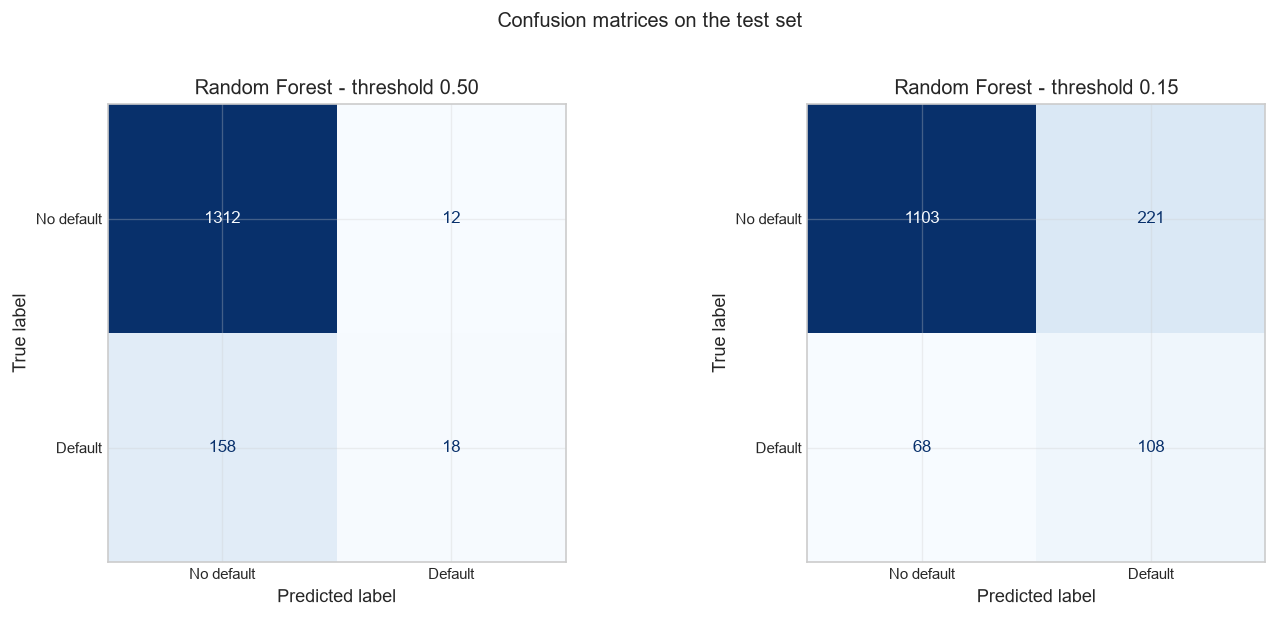

In [95]:
class_names: list[str] = ["No default", "Default"]
fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE_SQUARE)

for ax, threshold in zip(axes, [0.5, final_threshold]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predict_with_threshold(y_prob_final, threshold),
        display_labels=class_names,
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )
    ax.set_title(f"{BEST_MODEL} - threshold {threshold:.2f}")

fig.suptitle("Confusion matrices on the test set", y=1.02)
fig.tight_layout()
plt.show()


**Hallazgo.** Con umbral 0.5 el modelo casi no rechaza a nadie: sólo detecta 18 de los 176 incumplidos (y rechaza a 12 buenos clientes). Con 0.15 detecta 108 de 176 a cambio de rechazar a 221 buenos clientes. La matriz muestra el intercambio que la función de utilidad cuantifica.


## 11.0 Interpretabilidad: importancia por permutación

Se usa importancia por permutación sobre el test: cuánto cae el PR-AUC al desordenar cada variable. A diferencia de la importancia por impureza que usó el cuaderno original, no favorece a las variables continuas y se mide sobre datos no vistos.


In [96]:
perm = permutation_importance(
    final_model.estimator_,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

In [97]:
perm_importance: pd.DataFrame = (
    pd.DataFrame(
        {
            "mean_importance": perm.importances_mean,
            "std": perm.importances_std,
        },
        index=X_test.columns,
    )
    .sort_values("mean_importance", ascending=False)
)

display(perm_importance)

,mean_importance,std
utilizacion_credito,0.1566,0.0156
score_crediticio,0.0852,0.0087
consultas_buro_6m,0.0571,0.0142
relacion_deuda_ingreso,0.0087,0.0104
atrasos_12m,0.0016,0.0006
num_productos,-0.0004,0.0014
limite_credito,-0.0007,0.0029
edad,-0.0010,0.0015
cliente_premium,-0.0024,0.0010
antiguedad_laboral_meses,-0.0029,0.0014


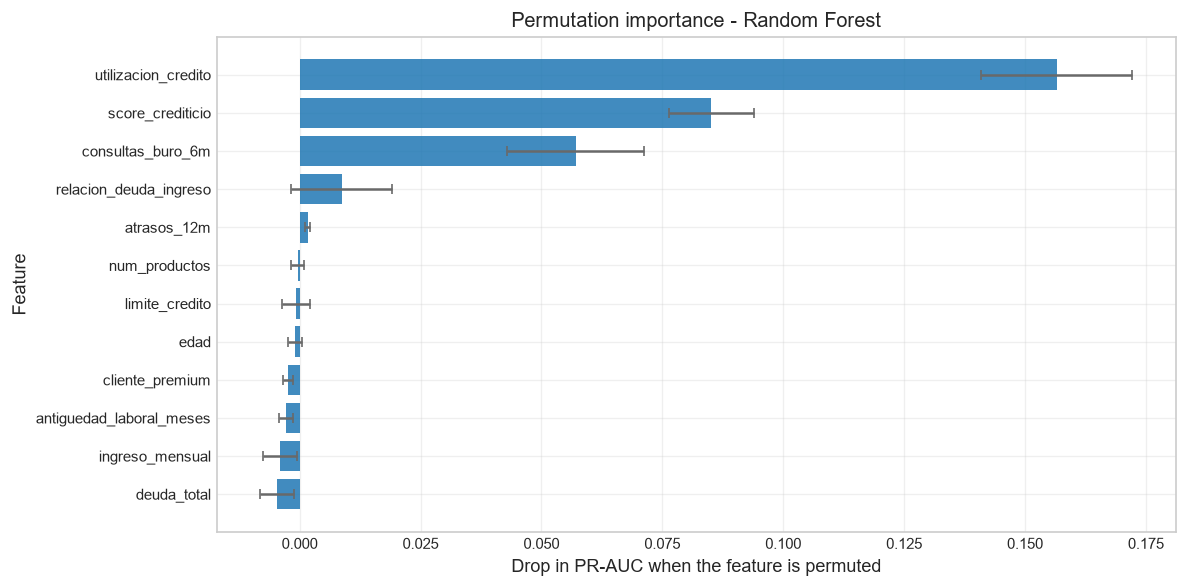

In [98]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE_WIDE)

features = perm_importance.index.to_numpy()[::-1]
means = perm_importance["mean_importance"].to_numpy()[::-1]
errors = perm_importance["std"].to_numpy()[::-1]

ax.barh(features, means, xerr=errors, alpha=0.85, ecolor="dimgray", capsize=3)
ax.set(
    xlabel="Drop in PR-AUC when the feature is permuted",
    ylabel="Feature",
    title=f"Permutation importance - {BEST_MODEL}",
)

fig.tight_layout()
plt.show()


**Hallazgo.** Sólo cuatro variables tienen un efecto material: `utilizacion_credito` (caída de 0.157 en PR-AUC), `score_crediticio` (0.085), `consultas_buro_6m` (0.057) y `relacion_deuda_ingreso` (0.009). Las demás tienen efecto cercano a cero o negativo (ruido), así que el modelo podría simplificarse sin perder desempeño. La baja importancia de `deuda_total` se debe en parte a que comparte información con `relacion_deuda_ingreso` y `utilizacion_credito` (3.6).


### 11.1 Explicaciones SHAP (globales y locales)


In [99]:
tree_model = final_model.estimator_.named_steps["model"]
explainer = shap.TreeExplainer(tree_model)
X_test_model: pd.DataFrame = final_model.estimator_.named_steps["imputer"].transform(X_test)
explanation = explainer(X_test_model)

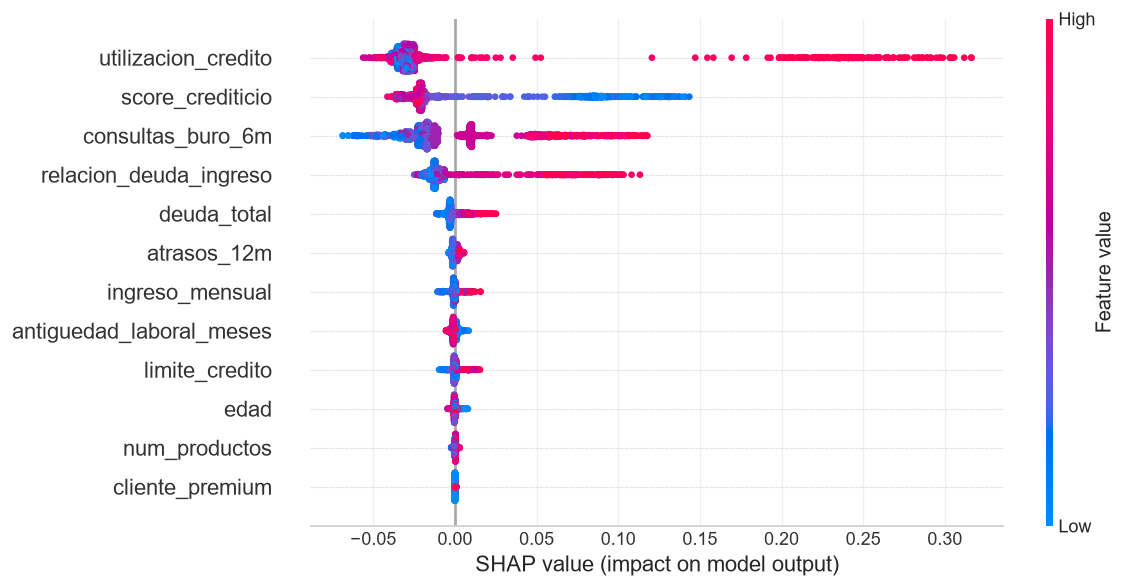

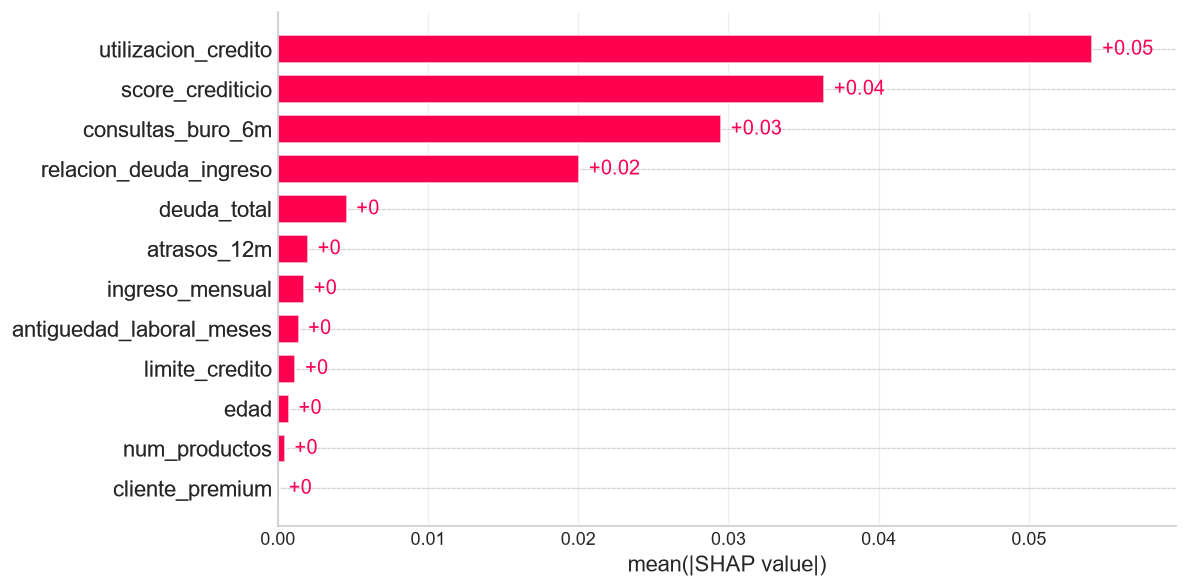

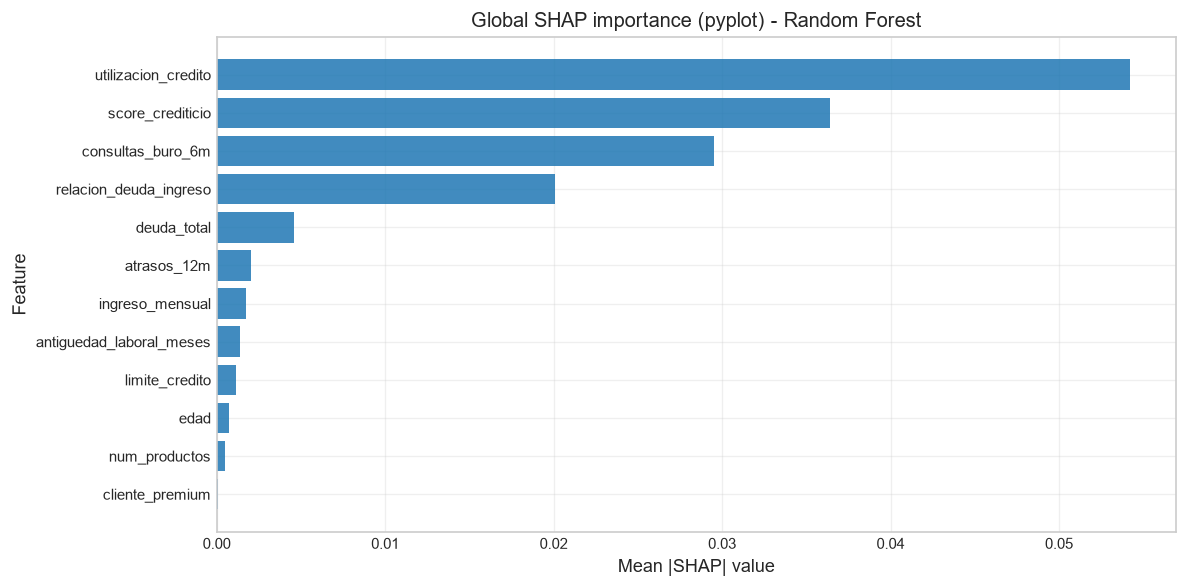

In [100]:
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]  # contributions toward the "default" class

# SHAP summary plots (matplotlib backend)
shap.plots.beeswarm(explanation, max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(*FIGURE_SIZE_WIDE)
fig.tight_layout()
plt.show()

shap.plots.bar(explanation, max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(*FIGURE_SIZE_WIDE)
fig.tight_layout()
plt.show()

# Pure pyplot companion: mean absolute SHAP values
mean_abs_shap = (
    pd.Series(np.abs(explanation.values).mean(axis=0), index=X_test.columns)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE_WIDE)
ax.barh(mean_abs_shap.index.to_numpy(), mean_abs_shap.to_numpy(), alpha=0.85)
ax.set(
    xlabel="Mean |SHAP| value",
    ylabel="Feature",
    title=f"Global SHAP importance (pyplot) - {BEST_MODEL}",
)
fig.tight_layout()
plt.show()


In [101]:
shap_summary: pd.DataFrame = pd.DataFrame(
    {
        "mean_abs_shap": np.abs(explanation.values).mean(axis=0),
        "value_vs_shap_corr": [
            np.corrcoef(X_test_model[column], explanation.values[:, position])[0, 1]
            for position, column in enumerate(X_test_model.columns)
        ],
    },
    index=X_test_model.columns,
).sort_values("mean_abs_shap", ascending=False)

display(shap_summary)

,mean_abs_shap,value_vs_shap_corr
utilizacion_credito,0.0542,0.6101
score_crediticio,0.0364,-0.7493
consultas_buro_6m,0.0295,0.8608
relacion_deuda_ingreso,0.0201,0.7803
deuda_total,0.0046,0.8385
atrasos_12m,0.0020,0.8840
ingreso_mensual,0.0018,0.6177
antiguedad_laboral_meses,0.0014,-0.6515
limite_credito,0.0012,0.5383
edad,0.0007,-0.3887


**Los cuatro factores más importantes y su significado de negocio** (la importancia por permutación y SHAP coinciden en el orden):

1. **Utilización de crédito:** qué proporción de sus líneas disponibles usa el cliente. Es el factor dominante: por encima de 0.8 aproximadamente el riesgo se dispara (contribuciones SHAP de hasta +0.30 en probabilidad; 39% de incumplimiento en el decil más alto). Un cliente que agota sus líneas tiene poco margen ante cualquier imprevisto. _Acción sugerida:_ alertas y límites dinámicos cuando la utilización supera 80%.
2. **Score crediticio:** resume el historial de pago. Los scores bajos (por debajo de 600 aproximadamente) elevan con claridad el riesgo; en scores altos el efecto se estabiliza. El historial sigue siendo informativo, pero no es suficiente por sí solo.
3. **Consultas al buró en los últimos 6 meses:** muchas consultas indican que el cliente busca crédito activamente en otras instituciones, una señal de posible estrés de liquidez. Con siete o más consultas, la tasa de incumplimiento supera 30%.
4. **Relación deuda/ingreso:** el apalancamiento del cliente. Cuando la deuda supera unas tres veces el ingreso mensual, el riesgo crece rápido (31% en el decil más alto).

Las cuatro direcciones son coherentes con la intuición crediticia (correlación entre el valor de la variable y su contribución SHAP: utilización +0.61, score −0.75, consultas +0.86, deuda/ingreso +0.78), lo que da confianza en el modelo. Edad, ingreso, antigüedad laboral y segmento premium prácticamente no influyen en la decisión.


Client (test index 157): P(default) = 0.690 | actual = 0 | decision = REJECT


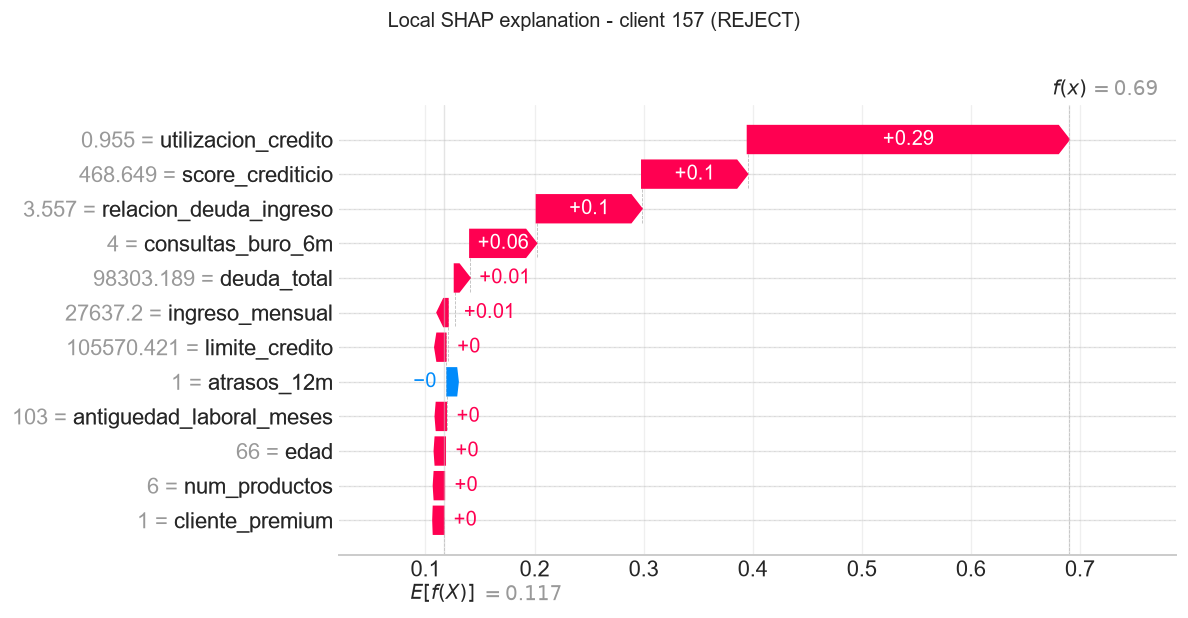

In [102]:
client_idx: int = int(np.argmax(y_prob_final))
decision = (
    "REJECT" if y_prob_final[client_idx] >= final_threshold else "APPROVE"
)

print(
    f"Client (test index {client_idx}): P(default) = "
    f"{y_prob_final[client_idx]:.3f} | actual = {y_test.iloc[client_idx]} | "
    f"decision = {decision}"
)

shap.plots.waterfall(explanation[client_idx], max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(*FIGURE_SIZE_WIDE)
fig.suptitle(
    f"Local SHAP explanation - client {client_idx} ({decision})",
    y=1.02,
)
fig.tight_layout()
plt.show()


**Explicación local.** El cliente con mayor probabilidad estimada (0.69) tiene utilización de 95.5%, score de 469, relación deuda/ingreso de 3.6 y 4 consultas recientes: los cuatro factores lo empujan hacia el rechazo desde el valor base de 0.117, que coincide con la tasa real de incumplimiento porque el modelo está calibrado. Aun así, este cliente **sí pagó**: una probabilidad de 69% implica que 3 de cada 10 clientes con ese perfil cumplen. El modelo decide sobre riesgo, no sobre certezas, y por eso la política se evalúa con la utilidad esperada de toda la cartera. A diferencia del cuaderno original, la explicación está en escala de probabilidad y no depende de una variable del futuro.


## 12.0 Conclusiones particulares


**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**


**Reporte ejecutivo para el CEO de CrediNova: auditoría del modelo de riesgo de incumplimiento a 90 días**

**Recomendación: no desplegar el modelo propuesto por el analista junior. En su lugar, desplegar la versión corregida (Random Forest con umbral de rechazo de 15%) mediante una prueba piloto controlada.**

**1. ¿Por qué no el modelo original?** Su "precisión del 100%" no es real. Proviene de dos fallas:

- Usa un dato que sólo se conoce **después** de otorgar el crédito (los días de atraso en los 30 días posteriores). Es como predecir el resultado de un partido viendo el marcador final: en producción ese dato no existe y el modelo fallaría.
- Se evaluó con clientes **artificiales** creados para balancear los datos, no con clientes reales, por lo que las cifras de utilidad presentadas no son confiables.

En total se documentaron 12 errores metodológicos (sección 4.1).

**2. ¿Qué se puede esperar realmente?** Con datos reales y sin información del futuro, el modelo corregido detecta a 6 de cada 10 clientes que incumplirán, rechazando al 22% de las solicitudes:

| Política (por cada 10,000 solicitudes) | Utilidad estimada | Incumplimientos aprobados |
| -------------------------------------- | ----------------- | ------------------------- |
| Sin modelo (aprobar a todos)           | USD 296,000       | 1,173                     |
| Modelo con umbral estándar (50%)       | USD 348,000       | 1,053                     |
| **Modelo recomendado (umbral 15%)**    | **USD 508,667**   | **453**                   |

Esto representa **+USD 212,667 por cada 10,000 solicitudes frente a no usar modelo (+72%)** y +USD 160,667 frente al umbral estándar. El intervalo de confianza de 95% va de USD 443,000 a USD 571,000.

**3. ¿Por qué Random Forest?** Rinde igual que XGBoost en utilidad (la diferencia no es estadísticamente significativa) y claramente mejor que un árbol simple (unos USD 40,000 más por cada 10,000 solicitudes). Su ventaja decisiva es que sus probabilidades son confiables: un riesgo estimado de 15% corresponde a un 15% real, lo que permite ajustar la política si cambian los costos sin reentrenar el modelo.

**4. ¿Qué explica el riesgo?** Utilización de crédito alta (más de 80%), score crediticio bajo, muchas consultas recientes al buró y deuda alta respecto al ingreso. Son factores intuitivos y accionables; la edad, el ingreso por sí solo y el segmento premium prácticamente no influyen.

**5. Condiciones para el despliegue:**

- **Validar con datos recientes:** los datos muestran patrones demasiado marcados (posiblemente sintéticos) y no traen fechas. Antes de producción hay que validar con una muestra histórica reciente, fuera del periodo de entrenamiento.
- **Lanzar como piloto:** por ejemplo, en 10–20% de las solicitudes o en modo sombra, comparando contra la política actual durante al menos un ciclo de 90 días.
- **Monitorear mensualmente** la tasa real de incumplimiento, la calibración y la distribución de las variables; recalcular el umbral si cambian los costos (USD 100 / USD 500) o la cartera.
- **Revisar la política de rechazos con Riesgos y Cumplimiento:** cerca de 17 de cada 100 buenos clientes serían rechazados. Para la zona gris conviene considerar alternativas al rechazo, como montos menores o garantías.
- **Control de datos:** asegurar que ninguna variable posterior a la fecha de evaluación pueda entrar al modelo (diccionario de datos con fecha de corte).

**Conclusión:** el _machine learning_ sí genera valor para CrediNova, pero el valor real es de unos USD 509,000 por cada 10,000 solicitudes, no el resultado perfecto que se prometió. Recomendamos aprobar el piloto del modelo corregido y no desplegar el original.

## 13.0 Conclusiones


Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

- Indica en qué casos el uso de LLMs fue de mayor provecho.
- En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


**Conclusiones generales**

- Un resultado perfecto en un problema de riesgo crediticio debe tratarse como una alerta, no como un éxito. La auditoría mostró que el 100% se explicaba por fuga de información y por un balanceo aplicado antes de separar los datos.
- El orden del flujo importa tanto como el modelo: primero la partición estratificada; después el remuestreo, la imputación y la búsqueda de hiperparámetros dentro de un `Pipeline` con validación cruzada; el umbral se elige en entrenamiento y el conjunto de prueba se usa una sola vez.
- Las métricas estadísticas (PR-AUC, ROC-AUC) sirven para ordenar el riesgo, pero la decisión se toma con la utilidad económica y con probabilidades calibradas. Sólo cambiar el umbral de 0.5 a 0.15 aumentó la utilidad 46% con el mismo modelo.
- Un modelo más complejo no siempre es mejor: Random Forest y XGBoost empatan en utilidad, y la calibración y la estabilidad definieron la elección.

**Uso de IA generativa (LLMs)**

Herramienta utilizada: **Claude Code** (modelo Claude Opus 5.5, de Anthropic), como asistente dentro del repositorio del curso.

_¿En qué casos fue de mayor provecho?_

- Revisar el cuaderno contra la rúbrica y las instrucciones para detectar qué objetivos faltaba responder de forma explícita.
- Generar código de apoyo repetitivo: gráficas del EDA con plotly y seaborn, validación de dominio, tabla de sensibilidad de umbrales y la comparación pareada por bootstrap.
- Ejecutar el cuaderno completo de principio a fin para verificar que no hubiera errores y que las cifras citadas en el texto coincidieran con las salidas.
- Elaborar un primer borrador de la redacción en español (hallazgos y reporte ejecutivo), que después se revisó y ajustó.

_¿En qué casos fue importante la intervención como experto?_

- La estructura metodológica del cuaderno (eliminar la variable con fuga, SMOTE dentro del pipeline, umbral por validación cruzada con `TunedThresholdClassifierCV`, bootstrap y SHAP del modelo final) ya estaba implementada cuando se usó el asistente; el asistente la validó y la complementó.
- Decidir con criterio de negocio: por ejemplo, que la calibración pesa más que una pequeña ventaja en PR-AUC, que los atípicos no se recortan porque son parte de los clientes de mayor riesgo y que el reporte para el CEO debe hablar de dinero y de riesgo, no de métricas.
- Verificar visualmente las gráficas generadas: dos eran engañosas en su primera versión (histogramas con _bins_ compartidos entre paneles y tasas de incumplimiento calculadas con grupos de un solo cliente) y se corrigieron.

_Limitaciones observadas:_ un LLM puede producir cifras o afirmaciones que suenan plausibles sin estar respaldadas por las salidas, por lo que todas las cifras del texto se verificaron contra las celdas ejecutadas. También tiende a proponer más análisis del necesario; hay que decidir qué aporta realmente a la pregunta de negocio.